# Explaining payment difficulty with a tree, a logistic regression and an EBM

**Explainable Artificial Intelligence (IAX), MUIA, Universidad Politécnica de Madrid, 2026/27**
Hands on project, Unit 2. Phase II (final submission)

| Name | Email |
|:--|:--|
| Pratham Jaikishan Bakshani Karamchandani |pratham.bakshani@alumnos.upm.es|
| Hugo Aguilar Sanchez | hugo.aguilar@alumnos.upm.es |
| Iker Rosales Saiz | iker.rosales@alumnos.upm.es |

In this project we want to predict whether a credit card client will have payment difficulties next month (`payment_difficulty_next_month`) and, more importantly, understand what each model learns. In this final phase we fit the three mandatory model families (a logical model, a logistic regression and an Explainable Boosting Machine), interpret each of them globally and on the same individual clients, compare where their explanations agree and where they don't, and use one of them to fill in `test.csv`.

## 0. Setup

Besides the usual stack we need `gosdt` for the tree (pinned to 0.1.8 as in the class notebook, because newer releases changed the API) and `interpret` for the EBM. The other logical learners of Phase I (`imodels`, `wittgenstein`) are not needed anymore, since we only keep the final tree.

In [1]:
import importlib.metadata
import subprocess
import sys

# we work with a local .venv, this just makes sure the notebook also runs in Colab
IN_COLAB = "google.colab" in sys.modules
REQUIRED = {"gosdt": "0.1.8", "interpret-core": None}


def installed_version(pkg):
    try:
        return importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError:
        return None


missing = [f"{p}=={v}" if v else p for p, v in REQUIRED.items()
           if installed_version(p) is None or (v and installed_version(p) != v)]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [2]:
import contextlib
import io
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
import pandas as pd
from gosdt import GOSDT
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

SEED = 42
TARGET = "payment_difficulty_next_month"

# two colours for the two classes (also "pushes towards no / yes" in local plots), gray for reference lines
C_NEG, C_POS, C_REF = "#2a78d6", "#eb6834", "#8a8984"
# one colour per model family, used in every comparison plot
C_MODEL = {"GOSDT": "#1baf7a", "Logistic regression": "#4a3aa7", "EBM": "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10,
})

In [3]:
DATA_DIR = Path(".")
if IN_COLAB and not (DATA_DIR / "train.csv").exists():
    from google.colab import files
    files.upload()  # upload train.csv and test.csv

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, " test:", test.shape)
train.head()

train: (25000, 17)  test: (5000, 16)


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan,payment_difficulty_next_month
0,CR26-120473,80000,male,university,married,54,0,0,0,24600,3700,10300,0.07,0,0.33,no,0
1,CR26-127004,20000,male,university,single,30,0,0,0,21100,21000,6700,0.05,0,1.98,no,0
2,CR26-116408,230000,female,graduate_school,married,35,0,0,0,1700,3600,5100,0.49,1,0.03,no,0
3,CR26-125768,150000,female,university,married,51,0,0,0,76100,-8800,15400,0.03,0,0.48,no,0
4,CR26-118040,500000,male,graduate_school,married,43,0,0,0,121600,26200,25000,0.03,0,0.25,yes,0


## 1. Quick look at the data

Basic checks first: types, missing values, duplicates and how balanced the target is.

In [4]:
CAT_COLS = ["sex", "education", "marital_status", "repayment_assistance_plan"]
NUM_COLS = [c for c in train.columns if c not in CAT_COLS + ["row_id", TARGET]]

print("missing values(train / test):", train.isna().sum().sum(),"/",test.isna().sum().sum())
print("row_id unique:", train.row_id.is_unique, "| overlap with test:", len(set(train.row_id) & set(test.row_id)))
print("duplicated rows ignoring row_id:", train.drop(columns="row_id").duplicated().sum())
print(f"positive rate: {train[TARGET].mean():.3f}  ->  majority class baseline accuracy = {1 - train[TARGET].mean():.3f}")
train[NUM_COLS].describe().T.round(2)

missing values(train / test): 0 / 0
row_id unique: True | overlap with test: 0
duplicated rows ignoring row_id: 18
positive rate: 0.212  ->  majority class baseline accuracy = 0.788


,count,mean,std,min,25%,50%,75%,max
credit_limit,25000.0,167740.95,129975.98,10000.0,50000.00,140000.00,240000.00,1000000.0
age,25000.0,35.50,9.24,21.0,28.00,34.00,41.00,79.0
latest_repayment_status,25000.0,-0.02,1.12,-2.0,-1.00,0.00,0.00,8.0
maximum_repayment_delay_6m,25000.0,0.68,1.07,0.0,0.00,0.00,2.00,8.0
delayed_months_6m,25000.0,0.83,1.55,0.0,0.00,0.00,1.00,6.0
average_bill_6m,25000.0,44910.44,63267.26,-56000.0,4700.00,21000.00,57100.00,877300.0
bill_change_sep_to_apr,25000.0,12389.51,44068.85,-403600.0,-3000.00,900.00,19900.00,708300.0
total_payment_6m,25000.0,31635.05,57337.82,0.0,6700.00,14400.00,33700.00,2314200.0
payment_to_bill_ratio_6m,25000.0,0.37,0.59,0.0,0.04,0.09,0.60,5.0
zero_payment_months_6m,25000.0,1.23,1.72,0.0,0.00,0.00,2.00,6.0


No missing values and no overlap between train and test ids. There are 18 duplicated rows if we ignore `row_id`, but with 25k clients and rounded amounts they can easily be different people with the same profile, so we keep them.

The target is imbalanced (21.2% positives), so the number to beat is **78.8% accuracy**. A few ranges are worth noting: `average_bill_6m` can be negative (credit in favour of the client), the money variables have very long tails (payments up to 2.3M) and `payment_to_bill_ratio_6m` and `utilization_sep` are capped at 5 and 2 by construction. None of this matters for a tree, which only looks at thresholds, but it does matter for the logistic regression, so we come back to it in section 4.

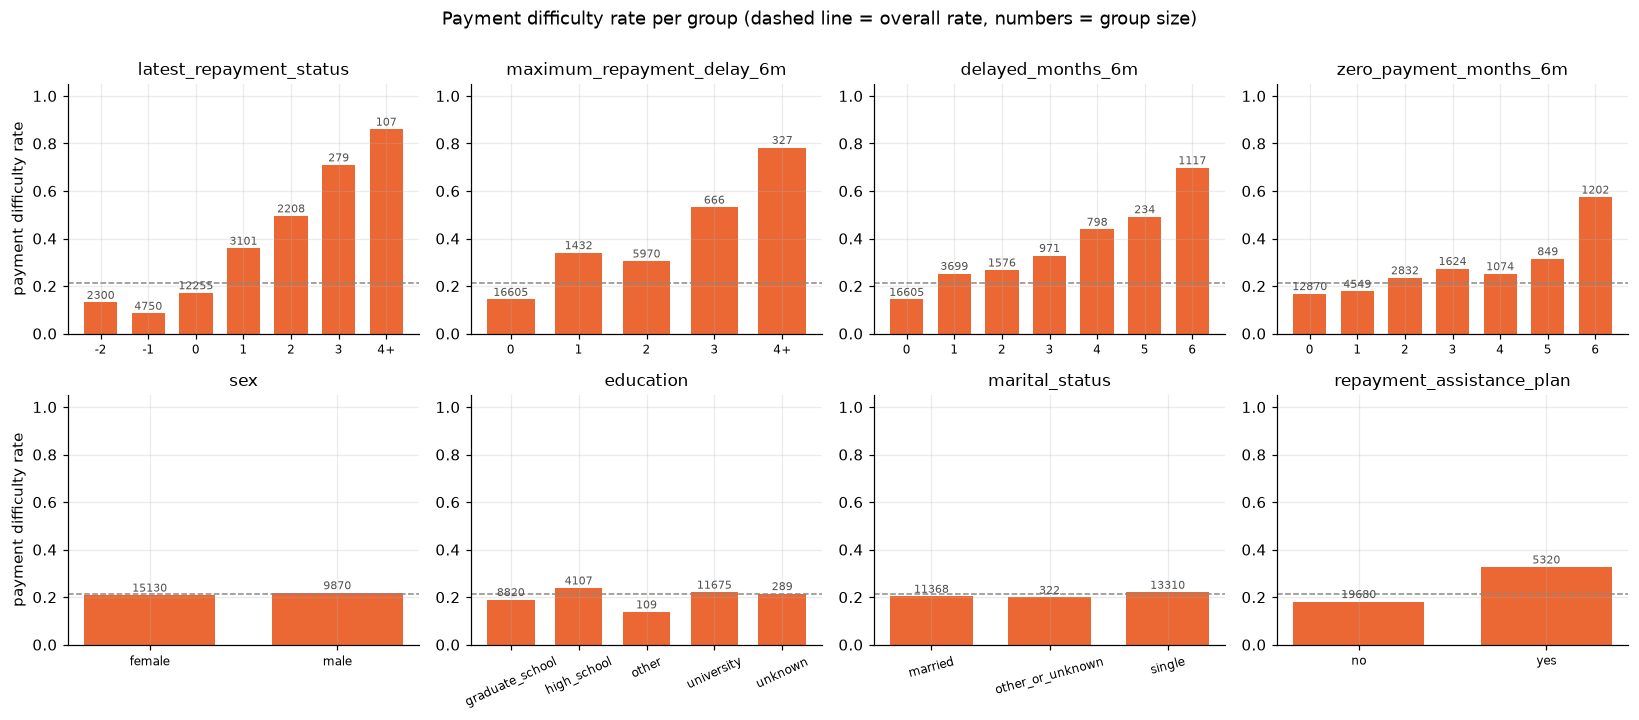

In [5]:
def rate_plot(ax, s, y, title, order=None):
    """Positive rate per group, with the group size written on each bar."""
    g = y.groupby(s).agg(["mean", "size"])
    if order is not None:
        g = g.reindex(order)
    ax.bar(g.index.astype(str), g["mean"], color=C_POS, width=0.7)
    ax.axhline(y.mean(), color=C_REF, ls="--", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.015, f"{n}", ha="center", fontsize=7, color="#52514e")
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", labelsize=8)


y_all = train[TARGET]
cap4 = lambda s: s.clip(upper=4).astype(str).replace("4", "4+")

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
rate_plot(axes[0, 0], cap4(train.latest_repayment_status), y_all, "latest_repayment_status",
          order=["-2", "-1", "0", "1", "2", "3", "4+"])
rate_plot(axes[0, 1], cap4(train.maximum_repayment_delay_6m), y_all, "maximum_repayment_delay_6m",
          order=["0", "1", "2", "3", "4+"])
rate_plot(axes[0, 2], train.delayed_months_6m, y_all, "delayed_months_6m")
rate_plot(axes[0, 3], train.zero_payment_months_6m, y_all, "zero_payment_months_6m")
for ax, c in zip(axes[1], CAT_COLS):
    rate_plot(ax, train[c], y_all, c)
axes[1, 1].tick_params(axis="x", rotation=25)
axes[1, 2].tick_params(axis="x", rotation=15)
for ax in axes[:, 0]:
    ax.set_ylabel("payment difficulty rate")
fig.suptitle("Payment difficulty rate per group (dashed line = overall rate, numbers = group size)", y=1.0)
plt.tight_layout()
plt.show()

The signal is clearly in the **repayment behaviour**. The difficulty rate grows almost monotonically with the delay variables, from around 15% with no delays up to 70% or more for clients delayed in all 6 months or with a maximum delay of 4+ months.

`latest_repayment_status` is the exception: the undocumented codes -2, -1 and 0 are not ordered (-1 has the lowest rate, 8.5%) and the real jump is between 0 and 1, when there is an actual delay. For `zero_payment_months_6m` the rate barely moves until 6, where it jumps to 57%, so "paid nothing in six months" is a very different situation from "skipped a couple of payments".

The demographic variables are almost flat. Sex in particular gives 20.8% vs 21.8%, so we don't expect the models to use it (we still audit the errors by sex in section 6). The assistance plan shows a higher rate (32.7% vs 18.1%), but the plan is offered to clients who are already struggling, so this is selection and not an effect of the plan.

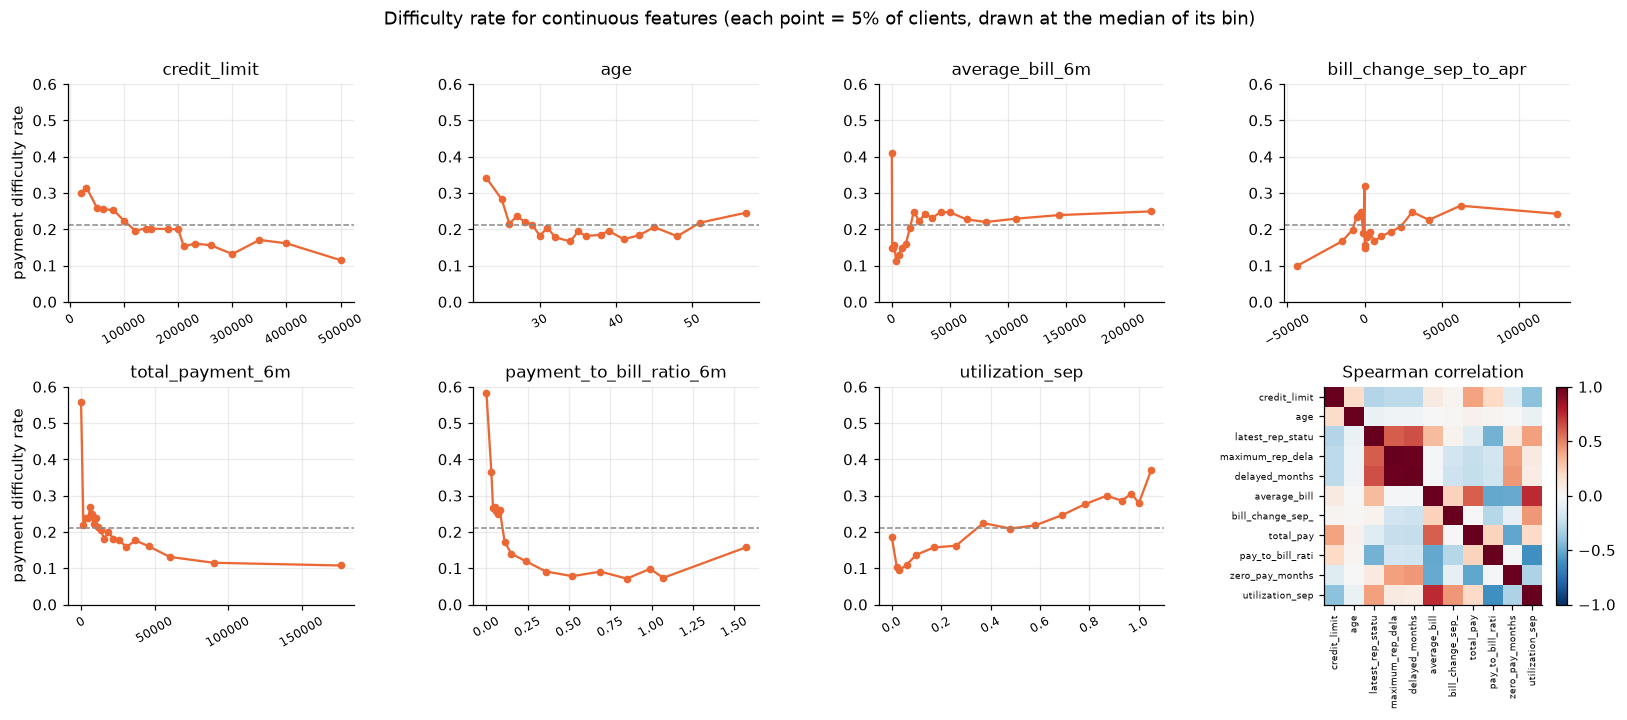

In [6]:
CONT_COLS = ["credit_limit", "age", "average_bill_6m", "bill_change_sep_to_apr",
             "total_payment_6m", "payment_to_bill_ratio_6m", "utilization_sep"]


fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.flat, CONT_COLS):
    # 20 quantile bins (5% of clients each), each point drawn at the median value of its bin
    bins = pd.qcut(train[c], q=20, duplicates="drop")
    g = (pd.DataFrame({"x": train[c], "y": y_all}).groupby(bins, observed=True)
         .agg(x=("x", "median"), rate=("y", "mean")))
    ax.plot(g.x, g.rate, marker="o", ms=4, lw=1.5, color=C_POS)
    ax.axhline(y_all.mean(), color=C_REF, ls="--", lw=1)
    ax.ticklabel_format(axis="x", style="plain")
    ax.tick_params(axis="x", labelsize=8, rotation=30)
    ax.set_title(c)
    ax.set_ylim(0, 0.6)
axes[0, 0].set_ylabel("payment difficulty rate")
axes[1, 0].set_ylabel("payment difficulty rate")

# redundancy between the numeric features
corr = train[NUM_COLS].corr(method="spearman")
ax = axes[1, 3]
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_COLS)))
ax.set_yticks(range(len(NUM_COLS)))
short = [c.replace("_6m", "").replace("repayment", "rep").replace("payment", "pay")[:16] for c in NUM_COLS]
ax.set_xticklabels(short, rotation=90, fontsize=6)
ax.set_yticklabels(short, fontsize=6)
ax.grid(False)
ax.set_title("Spearman correlation")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("Difficulty rate for continuous features (each point = 5% of clients, drawn at the median of its bin)", y=1.0)
plt.tight_layout()
plt.show()

For the continuous features the effects are weaker and not always monotonic:

* `payment_to_bill_ratio_6m` is the clearest one. Clients who paid nothing (ratio 0) have a ~60% difficulty rate, it stays around 25% up to 0.08 and drops below 10% from ~0.25 on. This showcases that clients paying their bills are less likely to default. Note that clients above 1.0, means that they pay even more than what were meant to because of their bills so they were inmersed in debt before and then we can see the payment difficulty rate being slightly higher.
* Exact zeros stand out in general: `total_payment_6m = 0` gives 56%, `average_bill_6m = 0` gives 41% and `bill_change_sep_to_apr = 0` gives 32%. These are probably inactive accounts or clients that simply stopped paying, and a tree can isolate them with a single threshold.
* `utilization_sep` goes up steadily (from ~10% to ~40% when the card is over the limit) meaning the clients that have already spent their credit are more likely to default. While `credit_limit` and `total_payment_6m` go down. Young clients (close to 20yo) are also riskier (34% at 23 years old).

The correlation matrix shows strong redundancy between the three delay variables and between bill, utilization and payment ratio. So we shouldn't read too much into which of them a tree picks (swapping one for a correlated one would probably give a similar tree), and the logistic regression coefficients of these groups will have to be read with care.

## 2. Preprocessing and evaluation setup

Every model receives the same raw table `X` (the 15 original variables, untouched) and does its own preprocessing inside `fit`. This way the transformations stay inside the cross validation folds and `test.csv` goes through exactly the same steps. The three families need quite different things:

| Family | What it needs | What we do |
|:--|:--|:--|
| Logical model (GOSDT) | binary features | 25 `feature >= threshold` indicators with the thresholds we chose in Phase I (section 3) |
| Logistic regression | inputs on a comparable scale, with a roughly linear relation to the log-odds | `latest_repayment_status` as categories, logs of the long-tailed money variables, one hot with an explicit reference level, standardisation (section 4) |
| EBM | no preprocessing | raw features: it bins the numeric ones and handles the categorical ones natively (section 5) |

The only transformation learned from data is the scaler of the logistic regression, and it lives inside a `Pipeline`, so it is refitted in every fold. The GOSDT thresholds are not learned: as usual with GOSDT, we set the cut points ourselves (where the difficulty rate jumps in the EDA, plus round values). Since we looked at the EDA of the whole training set to choose them, strictly speaking the validation folds had some influence on which questions the tree can ask. We think this effect is small: the thresholds are few and coarse, and in Phase I a data-driven alternative fitted inside each fold (threshold guessing) ended up with the same cut points and practically the same tree (section 3).

**Evaluation.** Same as in Phase I: one stratified 5 fold split (seed 42) shared by every model and used for hyperparameters, feature choices, model comparison and the classification threshold. We report accuracy because `test.csv` is graded on it, but with 21% positives predicting "no" for everyone already gives 0.788, so we also track ROC AUC (how well the model ranks clients by risk), balanced accuracy, recall (the share of clients with difficulty that the model actually flags) and F1 of the positive class. When choosing between configurations we don't just take the highest CV accuracy. Differences of a few thousandths are within the variation between folds, and the goal of the project is to understand the models, so we prefer the configuration that is easier to read and explain as long as it doesn't lose accuracy in a meaningful way.

In [7]:
X = train.drop(columns=["row_id", TARGET])
y = train[TARGET]
X_test = test[X.columns]
CAT_LEVELS = {c: sorted(train[c].unique()) for c in CAT_COLS}  # fixed by the data dictionary, not learned

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_evaluate(make_model, X, y, name=None, size=None):
    """5 fold CV with the shared split. Returns mean/std of the metrics, out of fold probabilities and the fold models."""
    rows, oof, fold_models = [], np.zeros(len(y)), []
    for tr, va in CV.split(X, y):
        model = make_model()
        t0 = time.time()
        model.fit(X.iloc[tr], y.iloc[tr])
        fit_time = time.time() - t0
        proba = np.asarray(model.predict_proba(X.iloc[va]))[:, 1]
        pred = np.asarray(model.predict(X.iloc[va])).astype(int)
        oof[va] = proba
        fold_models.append((model, va))
        rows.append({"accuracy": accuracy_score(y.iloc[va], pred),
                     "roc_auc": roc_auc_score(y.iloc[va], proba),
                     "balanced_acc": balanced_accuracy_score(y.iloc[va], pred),
                     "recall": recall_score(y.iloc[va], pred),
                     "f1": f1_score(y.iloc[va], pred),
                     "fit_s": fit_time,
                     "size": size(model) if size else np.nan})
    res = pd.DataFrame(rows)
    summary = pd.concat([res.mean().add_suffix("_mean"), res.std().add_suffix("_std")])
    summary.name = name
    return summary, oof, fold_models


def show_cv(*summaries):
    keys = ["accuracy", "roc_auc", "balanced_acc", "recall", "f1"]
    return pd.DataFrame([{k: f"{s[k + '_mean']:.4f} ± {s[k + '_std']:.4f}" for k in keys} | {"fit (s)": f"{s['fit_s_mean']:.1f}"}
                         for s in summaries], index=[s.name for s in summaries])


results, oof_probs, fold_models = {}, {}, {}
results["Majority baseline"], _, _ = cv_evaluate(lambda: DummyClassifier(strategy="most_frequent"), X, y, "Majority baseline")
show_cv(results["Majority baseline"])

,accuracy,roc_auc,balanced_acc,recall,f1,fit (s)
Majority baseline,0.7879 ± 0.0001,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0


**Clients for the local explanations.** The statement asks for the same instances in the three models, with at least one of each class. We keep the three clients fixed in Phase I (drawn at random with the seed from three profiles):

* **CR26-102000** (difficulty): the clear risky profile. 23 years old, 3 months late right now, late in all six months, paid nothing.
* **CR26-129090** (difficulty): a positive with a clean history. Never late, paid 100% of a small bill.
* **CR26-126238** (no difficulty): an ordinary good client.

In section 6 we add a fourth client on which the models disagree.

In [8]:
LOCAL_IDS = ["CR26-102000", "CR26-129090", "CR26-126238"]
LOCAL_IDX = [train.index[train.row_id == r][0] for r in LOCAL_IDS]
train.loc[LOCAL_IDX].set_index("row_id").T

row_id,CR26-102000,CR26-129090,CR26-126238
credit_limit,10000,180000,10000
sex,female,male,male
education,graduate_school,graduate_school,university
marital_status,single,single,married
age,23,31,50
latest_repayment_status,3,-1,0
maximum_repayment_delay_6m,7,0,0
delayed_months_6m,6,0,0
average_bill_6m,2400,900,5900
bill_change_sep_to_apr,0,0,-2500


## 3. Model family 1: logical model (GOSDT)

**What we did in Phase I.** We compared five logical learners with the same 5 fold CV:

| Model | Size | CV accuracy | CV AUC |
|:--|:--|:--|:--|
| CART (`max_depth=4`, `min_samples_leaf=200`) | 14 leaves | 0.8133 | 0.747 |
| **GOSDT (`depth_budget=4`, `regularization=0.0005`)** | **7 leaves** | **0.8154** | 0.649 |
| Greedy rule list | 7 rules + else | 0.7879 (never says "yes") | 0.719 |
| Bayesian rule list | 13 rules | 0.8053 | 0.744 |
| RIPPER (`max_rules=8`, `max_rule_conds=3`) | 8 rules + default | 0.8043 | 0.588 |
| GOSDT with threshold guessing | 7 leaves | 0.8136 | 0.652 |
| Gradient boosting (black box, reference only) | 100 trees | 0.8164 | 0.768 |

GOSDT had the best accuracy with the smallest model, and a wider search (finer thresholds, other depths and penalties) kept converging to the same 7 leaf tree. The rule models were either less accurate (BRL, RIPPER) or useless as classifiers (the greedy list), and harder to read: a rule list only makes sense read in order, and RIPPER's rules overlapped. The black box was only 0.1 points more accurate.

**How GOSDT learns.** Instead of growing the tree greedily like CART, GOSDT searches (with branch and bound and dynamic programming) for the tree $T$ that minimises the training error plus a fixed cost per leaf:

$$\min_{T}\;\; \underbrace{\frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\big[\,\hat y_T(x_i) \neq y_i\,\big]}_{\text{misclassification rate}} \;+\; \lambda \cdot \underbrace{\#\text{leaves}(T)}_{\text{size}} \qquad \text{(at most 3 levels of questions)}$$

With $\lambda = 0.0005$ (`regularization`) and `depth_budget=4` (which counts the leaf level, so three levels of questions), a new leaf only pays off if it fixes at least $\lambda n \approx 12$ of the 25,000 training clients, so every leaf of the final tree has to change predictions to be there. Each leaf predicts its majority class, and we use its share of positives as $P(\text{yes})$.

GOSDT needs binary features, so someone has to decide the cut points. We did it ourselves, which is the usual way of using GOSDT, with 25 `feature >= threshold` indicators placed where the EDA shows the difficulty rate jumping (for example `latest_repayment_status >= 1`, `delayed_months_6m >= 6`, `payment_to_bill_ratio_6m >= 0.03`) plus some round values (`age >= 25`, `credit_limit >= 150000`). As a check, in Phase I we also tried threshold guessing (McTavish et al., 2022), which lets a small boosting model propose the thresholds inside each training fold: it rebuilt practically the same tree with the same cut points, so our choice is not an artefact of looking at the data.

To keep the notebook focused, **in Phase II we keep only that GOSDT tree as our logical model** and don't repeat the search. We refit it in the shared CV (for the summary table and the out of fold probabilities) and on the whole training set (for the interpretation). The wrapper below binarises the raw data itself, so GOSDT receives the same `X` as the other two models.

In [9]:
THRESHOLDS = {
    "latest_repayment_status": [0, 1, 2],
    "maximum_repayment_delay_6m": [1, 2, 3],
    "delayed_months_6m": [1, 3, 6],
    "zero_payment_months_6m": [1, 3, 6],
    "payment_to_bill_ratio_6m": [0.03, 0.1, 0.5],
    "total_payment_6m": [2500, 10000],
    "utilization_sep": [0.5, 0.9],
    "credit_limit": [50000, 150000],
    "age": [25, 45],
    "bill_change_sep_to_apr": [0],
}


def make_binary_features(df, thresholds=THRESHOLDS):
    cols = {f"{f}_ge_{t}": (df[f] >= t).astype(int) for f, ts in thresholds.items() for t in ts}
    cols["assistance_plan"] = (df["repayment_assistance_plan"] == "yes").astype(int)
    return pd.DataFrame(cols, index=df.index)


def readable(name, holds):
    """'age_ge_25' + True -> 'age >= 25'."""
    if name == "assistance_plan":
        return "assistance plan" if holds else "no assistance plan"
    f, t = name.rsplit("_ge_", 1)
    return f"{f} {'>=' if holds else '<'} {t}"


class GOSDTClassifier(ClassifierMixin, BaseEstimator):
    """GOSDT with a scikit-learn interface. It binarises the raw features itself, so it takes the same X as the other models.
    Since GOSDT only predicts labels, P(yes) of a leaf is the positive rate of the training clients in it."""

    def __init__(self, regularization=0.0005, depth_budget=4, time_limit=60):
        self.regularization = regularization
        self.depth_budget = depth_budget
        self.time_limit = time_limit

    def fit(self, X, y):
        self.model_ = GOSDT({"regularization": self.regularization, "depth_budget": self.depth_budget,
                             "time_limit": self.time_limit, "similar_support": False})
        with contextlib.redirect_stdout(io.StringIO()):  # gosdt prints a lot
            self.model_.fit(make_binary_features(X), y)
        self.tree_, self.classes_ = self.model_.tree.source, np.array([0, 1])
        leaf, pred = self._walk(X)
        self.leaf_summary_ = (pd.DataFrame({"leaf": leaf, "y": y, "prediction": pred}).groupby("leaf")
                              .agg(n=("y", "size"), p_yes=("y", "mean"), prediction=("prediction", "first"))
                              .sort_values("p_yes"))
        self.prior_ = y.mean()
        return self

    def _walk(self, X):
        """Leaf (as a readable path) and GOSDT's prediction for every row, walking the tree with boolean masks."""
        Xb = make_binary_features(X)
        leaf, pred = pd.Series("", index=X.index, dtype=object), pd.Series(0, index=X.index)

        def walk(node, mask, path):
            if node.get("name") == "class":
                leaf[mask], pred[mask] = " and ".join(path), int(node["prediction"])
                return
            holds = Xb[node["name"]] == node.get("reference", 1)
            walk(node["true"], mask & holds, path + [readable(node["name"], True)])
            walk(node["false"], mask & ~holds, path + [readable(node["name"], False)])

        walk(self.tree_, pd.Series(True, index=X.index), [])
        return leaf, pred

    def leaves(self, X):
        return self._walk(X)[0]

    def predict(self, X):
        return self._walk(X)[1].to_numpy()

    def predict_proba(self, X):
        p = self.leaves(X).map(self.leaf_summary_["p_yes"]).fillna(self.prior_).to_numpy()
        return np.c_[1 - p, p]

    def n_leaves(self):
        return self.model_.leaves()


GOSDT_PARAMS = {"regularization": 0.0005, "depth_budget": 4}  # chosen in Phase I
results["GOSDT"], oof_probs["GOSDT"], fold_models["GOSDT"] = cv_evaluate(
    lambda: GOSDTClassifier(**GOSDT_PARAMS), X, y, "GOSDT", size=lambda m: m.n_leaves())
gosdt = GOSDTClassifier(**GOSDT_PARAMS).fit(X, y)

leaf_table = gosdt.leaf_summary_.assign(
    share_of_clients=lambda d: d.n / len(y),
    share_of_all_positives=lambda d: d.n * d.p_yes / y.sum())
print(f"leaves: {gosdt.n_leaves()}")
display(leaf_table.round(3))
show_cv(results["GOSDT"])

leaves: 7


,n,p_yes,prediction,share_of_clients,share_of_all_positives
leaf,,,,,
age >= 25 and payment_to_bill_ratio_6m >= 0.03 and delayed_months_6m < 6,20472,0.155,0,0.819,0.599
age < 25 and latest_repayment_status < 1,1625,0.243,0,0.065,0.074
age < 25 and latest_repayment_status >= 1 and payment_to_bill_ratio_6m >= 0.1,183,0.404,0,0.007,0.014
age >= 25 and payment_to_bill_ratio_6m < 0.03 and maximum_repayment_delay_6m < 1,630,0.424,0,0.025,0.050
age >= 25 and payment_to_bill_ratio_6m >= 0.03 and delayed_months_6m >= 6,847,0.638,1,0.034,0.102
age >= 25 and payment_to_bill_ratio_6m < 0.03 and maximum_repayment_delay_6m >= 1,804,0.680,1,0.032,0.103
age < 25 and latest_repayment_status >= 1 and payment_to_bill_ratio_6m < 0.1,439,0.688,1,0.018,0.057


,accuracy,roc_auc,balanced_acc,recall,f1,fit (s)
GOSDT,0.8154 ± 0.0020,0.6494 ± 0.0082,0.6132 ± 0.0030,0.2619 ± 0.0054,0.3758 ± 0.0068,2.3


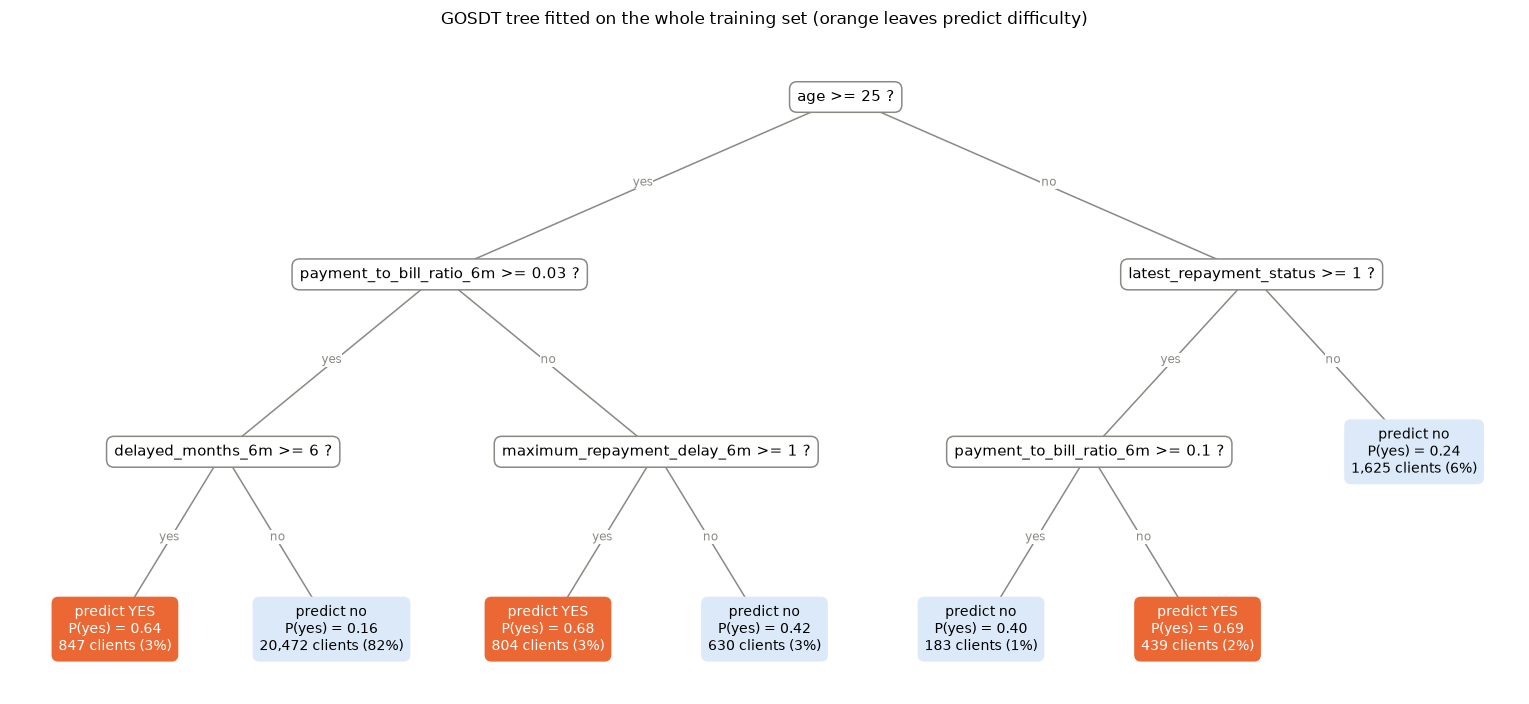

In [10]:
def draw_gosdt(model, ax):
    """Draw the GOSDT tree: questions in white boxes, leaves coloured by prediction with size and P(yes)."""
    stats, next_x = model.leaf_summary_, iter(range(100))

    def place(node, depth, path):
        if node.get("name") == "class":
            x, s = next(next_x), stats.loc[" and ".join(path)]
            yes = s.prediction == 1
            ax.text(x, -depth, f"predict {'YES' if yes else 'no'}\nP(yes) = {s.p_yes:.2f}\n{int(s.n):,} clients ({s.n / len(y):.0%})",
                    ha="center", va="center", fontsize=9, color="white" if yes else "black",
                    bbox=dict(boxstyle="round,pad=0.5", fc=C_POS if yes else "#dce9f8", ec="none"))
            return x
        name = node["name"]
        xs = [place(node[b], depth + 1, path + [readable(name, b == "true")]) for b in ["true", "false"]]
        x = np.mean(xs)
        for xc, lab in zip(xs, ["yes", "no"]):
            ax.plot([x, xc], [-depth, -depth - 1], color=C_REF, lw=1, zorder=0)
            ax.text((x + xc) / 2, -depth - 0.5, lab, ha="center", fontsize=8, color=C_REF,
                    bbox=dict(fc="white", ec="none", pad=0.5))
        ax.text(x, -depth, readable(name, True) + " ?", ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=C_REF))
        return x

    place(model.tree_, 0, [])
    ax.axis("off")
    ax.margins(x=0.08, y=0.12)


fig, ax = plt.subplots(figsize=(14, 6.5))
draw_gosdt(gosdt, ax)
ax.set_title("GOSDT tree fitted on the whole training set (orange leaves predict difficulty)")
plt.tight_layout()
plt.show()

**Global interpretation.** The tree reads as three short checks:

* **25 or older** (91% of the clients). If they pay at least 3% of what they are billed, the only thing that makes the tree say "yes" is **being late in all six months** (64% difficulty). If they pay less than 3%, it says "yes" as soon as **they have been late at least once** (68%). Paying almost nothing but never having been late stays at "no", even with 42% difficulty.
* **Under 25.** The tree asks about the present: if they are **late right now and paying less than 10% of their bills**, "yes" (69%). If they are not late now, "no" (24%).

So the model flags three profiles: the chronic late payer, the client who pays almost nothing and has been late, and the young client who is late now and pays little. Every question is about repayment behaviour except age. Money amounts (bill, limit, utilisation), the assistance plan and the other demographic variables are never asked about, even though they were available as binary features.

Age at the root does not mean that age is the strongest variable. With only two more questions per branch, splitting by age lets the tree be stricter with young clients: under 25, being late now plus paying little is already enough evidence. The EBM in section 5 shows a jump in risk at exactly 25, so the cut is not an accident of the optimiser.

The leaf table explains the low recall (0.26 in the CV: the tree flags only about one in four clients who end up having difficulty). The big leaf (age 25 or more, pays 3% or more, not late every month) holds **82% of the clients and 60% of all the positives** at a 15.5% rate. The three "yes" leaves together cover only 8% of the clients and 26% of the positives, so the tree only says "yes" when the profile is very clear. The leaves at 40% and 42% are the ones it would flag first if we cared about recall. The low AUC (0.649) has the same cause: with 7 leaves the model only produces 7 different scores, and most clients share one.

In [11]:
leaf_of = gosdt.leaves(X)
pd.DataFrame({"row_id": train.row_id[LOCAL_IDX].values, "true class": y[LOCAL_IDX].values,
              "GOSDT prediction": gosdt.predict(X.loc[LOCAL_IDX]),
              "P(yes) of the leaf": gosdt.predict_proba(X.loc[LOCAL_IDX])[:, 1].round(3),
              "leaf (path from the root)": leaf_of[LOCAL_IDX].values}).set_index("row_id")

,true class,GOSDT prediction,P(yes) of the leaf,leaf (path from the root)
row_id,,,,
CR26-102000,1,1,0.688,age < 25 and latest_repayment_status >= 1 and ...
CR26-129090,1,0,0.155,age >= 25 and payment_to_bill_ratio_6m >= 0.03...
CR26-126238,0,0,0.155,age >= 25 and payment_to_bill_ratio_6m >= 0.03...


**Local interpretation.** For a tree, the explanation is the path from the root to the leaf:

* **CR26-102000 (difficulty)** goes down the young branch: under 25, late right now (status 3) and paying under 10% (it paid 0%), so "yes" with 69%. This client is also late in all six months and has six months without paying, but the tree never looks at that, because the path ends before. A path is a sufficient reason, not a weighing of all the evidence. If the same client were 25, it would land in the "pays under 3% and has been late" leaf (68%): same answer, different explanation.
* **CR26-129090 (difficulty)** and **CR26-126238 (no difficulty)** fall in the same big leaf (15.5%), so the tree can't tell them apart. The positive client has a spotless record (never late, paid 101% of the bill), so from the tree's point of view it looks like the 82% majority. Most of the false negatives are like this.

## 4. Model family 2: logistic regression

A logistic regression writes the log-odds of difficulty as a weighted sum of the inputs:

$$\log \frac{P(\text{yes} \mid x)}{1 - P(\text{yes} \mid x)} \;=\; \beta_0 + \sum_{j=1}^{p} \beta_j z_j, \qquad P(\text{yes} \mid x) = \frac{1}{1 + e^{-(\beta_0 + \sum_j \beta_j z_j)}}$$

where $z_j$ are the (transformed and standardised) inputs. Each $\beta_j$ is the change in log-odds when $z_j$ grows by one unit with everything else fixed. That is a very compact explanation (one number per variable), but only if the inputs are prepared so that "one weight per variable" makes sense. From the EDA:

* `latest_repayment_status` is not monotonic in its negative codes (-1 is safer than both -2 and 0) and the risk jumps after 0. One slope can't represent that, so we one hot encode it with **code 0 as the reference** (the most frequent one) and group codes 3 to 8 (only 386 clients). We still don't give the codes a meaning, each coefficient just compares a code with code 0.
* The money variables have very long tails and their effect is concentrated at the low end. A linear term would be driven by a few extreme clients, so we take logs: `log` for `credit_limit`, `log1p` for `total_payment_6m` (it has zeros), a signed log for `average_bill_6m` and `bill_change_sep_to_apr` (they can be negative) and `log(x + 0.01)` for `payment_to_bill_ratio_6m`. With the last one, going from paying 0% to 3% of the bill weighs about as much as going from 30% to 300%, which is what the EDA suggests.
* The counts (delayed months, months without payment, maximum delay), age and utilisation stay linear.
* Categorical variables are one hot encoded with the most frequent level as reference (female, university, single, no assistance plan).
* Everything is standardised, so the penalty treats all coefficients equally and they are comparable with each other (change in log-odds per standard deviation).

First we check with CV that these choices help, starting from the naive version (raw numbers, same one hot for the categorical variables) and adding one change at a time, with the penalty practically off (`C=1`).

In [12]:
REFERENCE = {"sex": "female", "education": "university", "marital_status": "single", "repayment_assistance_plan": "no"}
MONEY = ["credit_limit", "average_bill_6m", "bill_change_sep_to_apr", "total_payment_6m", "payment_to_bill_ratio_6m"]


def slog(s):
    """Signed log: compresses the long tails and keeps the sign of bills that can be negative."""
    return np.sign(s) * np.log1p(np.abs(s))


def lr_features(df, status_as_category=True, log_money=True):
    """Design matrix of the logistic regression (stateless, so it can live inside the CV pipeline)."""
    out = pd.DataFrame({"age": df.age}, index=df.index)
    if status_as_category:  # code 0 is the reference, codes 3 to 8 are grouped (only 386 clients)
        status = df.latest_repayment_status.clip(upper=3)
        for v in [-2, -1, 1, 2, 3]:
            out[f"latest_repayment_status={v}{'+' if v == 3 else ''}"] = (status == v).astype(float)
    else:
        out["latest_repayment_status"] = df.latest_repayment_status
    for c in ["maximum_repayment_delay_6m", "delayed_months_6m", "zero_payment_months_6m", "utilization_sep"]:
        out[c] = df[c]
    if log_money:
        out["log(credit_limit)"] = np.log(df.credit_limit)
        out["slog(average_bill_6m)"] = slog(df.average_bill_6m)
        out["slog(bill_change_sep_to_apr)"] = slog(df.bill_change_sep_to_apr)
        out["log1p(total_payment_6m)"] = np.log1p(df.total_payment_6m)
        out["log(payment_to_bill_ratio_6m+0.01)"] = np.log(df.payment_to_bill_ratio_6m + 0.01)
    else:
        for c in MONEY:
            out[c] = df[c]
    for c, ref in REFERENCE.items():  # one hot with an explicit reference level (the most frequent one)
        for level in CAT_LEVELS[c]:
            if level != ref:
                out[f"{c}={level}"] = (df[c] == level).astype(float)
    return out


def raw_name(col):
    """'log(credit_limit)' -> 'credit_limit', 'education=other' -> 'education'."""
    return re.sub(r"^\w+\(([a-z0-9_]+)[^)]*\)$", r"\1", col).split("=")[0]


def make_lr(C=1.0, **feature_kw):
    # l1_ratio=1 is the lasso penalty; saga is the solver that supports it with an unpenalised intercept
    return make_pipeline(FunctionTransformer(lr_features, kw_args=feature_kw), StandardScaler(),
                         LogisticRegression(penalty="elasticnet", l1_ratio=1.0, solver="saga", C=C, max_iter=5000,
                                            random_state=SEED))


n_coefs = lambda m: int((m[-1].coef_ != 0).sum())
variants = {"raw numeric features": dict(status_as_category=False, log_money=False),
            "+ latest_repayment_status as category": dict(status_as_category=True, log_money=False),
            "+ logs of the money variables": dict(status_as_category=True, log_money=True)}
lr_variants = [cv_evaluate(lambda: make_lr(C=1.0, **kw), X, y, name, size=n_coefs)[0] for name, kw in variants.items()]
show_cv(*lr_variants)

,accuracy,roc_auc,balanced_acc,recall,f1,fit (s)
raw numeric features,0.8107 ± 0.0038,0.7517 ± 0.0063,0.6044 ± 0.0074,0.2461 ± 0.0138,0.3553 ± 0.0173,0.3
+ latest_repayment_status as category,0.8107 ± 0.0039,0.7539 ± 0.0073,0.6060 ± 0.0087,0.2506 ± 0.0172,0.3594 ± 0.0204,0.3
+ logs of the money variables,0.8150 ± 0.0047,0.7624 ± 0.0073,0.6247 ± 0.0085,0.2944 ± 0.0155,0.4029 ± 0.0185,0.4


Encoding `latest_repayment_status` as categories hardly changes accuracy (0.8107 to 0.8106, AUC +0.002), because what it fixes is the order of the negative codes, and those clients are predicted "no" either way. We keep it anyway: one slope over undocumented codes would make the coefficient meaningless. **The logs are what matter**: accuracy +0.4 points (0.8150), AUC 0.754 to 0.762, recall 0.25 to 0.29 and F1 0.36 to 0.40. Without them the model can only say "more payment, less risk" at the same rate across the whole range. With them it can say that going from paying 0% to 3% matters a lot and going from 50% to 100% doesn't.

**The price of the logs is interpretability.** With a raw variable the coefficient reads directly: every extra 10,000 NTD paid changes the log-odds by the same fixed amount, wherever the client starts. With a log, the fixed effect is per *doubling*: going from 1,000 to 2,000 NTD paid weighs the same as going from 50,000 to 100,000, so the effect of "one more unit" depends on the client's starting point and can't be summarised in one number. The statement is still readable ("doubling the payment multiplies the odds by X"), but less direct, and it only applies to the five transformed variables (the delays, counts, utilisation, age and the categories keep their plain per unit reading). So we keep both versions as results: the raw one, more literal but worse at describing the data, and the log one, which fits better and is the one we interpret below.

**Regularisation and feature selection.** The delay variables and the bill variables are strongly correlated, which makes unpenalised coefficients unstable and hard to read. We use a lasso (L1) penalty and tune its strength `C` with the CV. scikit-learn fits the coefficients by minimising the log-loss of the training clients plus the sum of the absolute values of the coefficients:

$$\min_{\beta_0,\,\beta}\;\; \lVert \beta \rVert_1 \;+\; C \sum_{i=1}^{n} \Big[ -y_i \log p_i - (1 - y_i)\log(1 - p_i) \Big], \qquad p_i = \sigma\Big(\beta_0 + \sum_j \beta_j z_{ij}\Big)$$

The intercept is not penalised. A small `C` sets many coefficients to exactly zero, so the same grid also does the feature selection. As we'll see, accuracy barely moves along most of the grid, so we choose `C` mainly for readability.

best CV accuracy in the grid 0.8153 | chosen C = 0.01 -> 0.8151


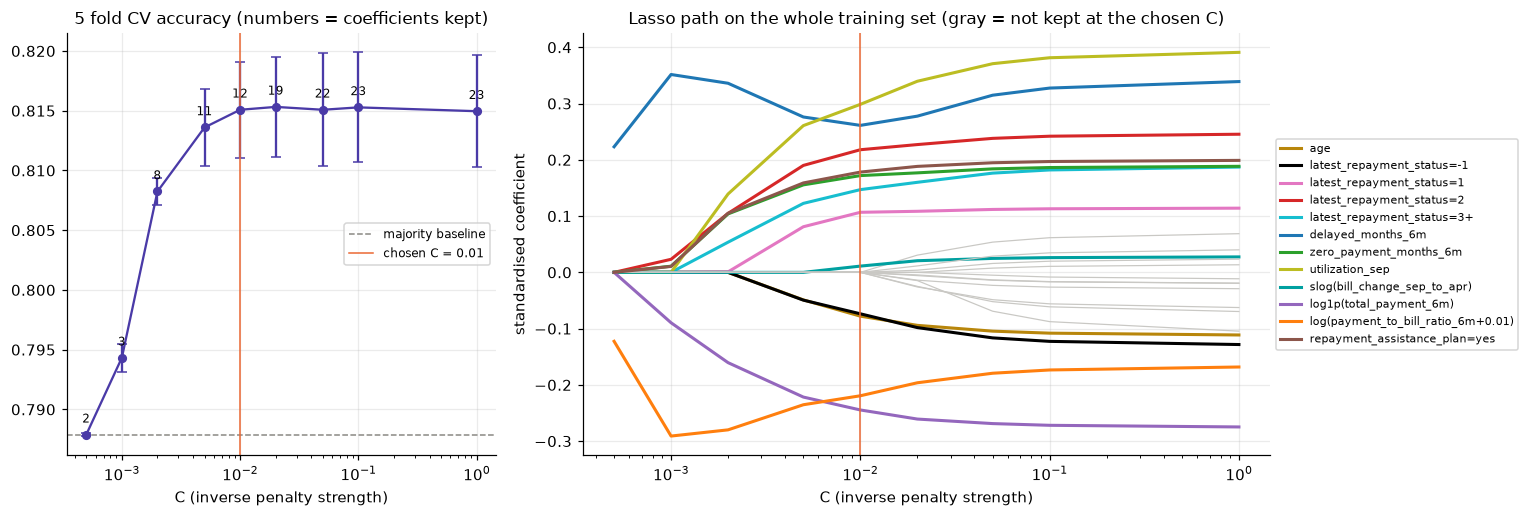

coefficients at C=1 of the variables the chosen model drops:
latest_repayment_status=-2        -0.070
maximum_repayment_delay_6m        -0.104
log(credit_limit)                  0.069
slog(average_bill_6m)             -0.063
sex=male                          -0.029
education=graduate_school          0.023
education=high_school              0.040
education=other                   -0.011
education=unknown                  0.013
marital_status=married            -0.019
marital_status=other_or_unknown   -0.019


,C,non zero coefs (mean over folds),accuracy,acc_std,roc_auc,f1
0,0.0005,2.0,0.7879,0.0001,0.7179,0.0000
1,0.0010,3.0,0.7943,0.0012,0.7337,0.0633
2,0.0020,8.0,0.8082,0.0011,0.7498,0.2585
3,0.0050,11.0,0.8136,0.0032,0.7588,0.3639
4,0.0100,11.8,0.8151,0.0040,0.7605,0.3877
5,0.0200,19.0,0.8153,0.0042,0.7611,0.3960
6,0.0500,22.4,0.8151,0.0047,0.7621,0.3997
7,0.1000,22.8,0.8153,0.0046,0.7623,0.4020
8,1.0000,22.8,0.8150,0.0047,0.7624,0.4029


In [13]:
C_GRID = [0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 1.0]
lr_grid, lr_cv, paths = [], {}, {}
for C in C_GRID:
    s, oof, fm = cv_evaluate(lambda: make_lr(C), X, y, f"LR C={C}", size=n_coefs)
    lr_cv[C] = (s, oof, fm)
    lr_grid.append({"C": C, "non zero coefs (mean over folds)": s.size_mean, "accuracy": s.accuracy_mean,
                    "acc_std": s.accuracy_std, "roc_auc": s.roc_auc_mean, "f1": s.f1_mean})
    full = make_lr(C).fit(X, y)
    paths[C] = pd.Series(full[-1].coef_[0], index=full[0].transform(X.head(1)).columns)
lr_grid = pd.DataFrame(lr_grid)
paths = pd.DataFrame(paths).T

best_acc = lr_grid.accuracy.max()
LR_C = 0.01  # our choice after looking at the curves below (see the discussion after this cell)
print(f"best CV accuracy in the grid {best_acc:.4f} | chosen C = {LR_C} -> {lr_grid.set_index('C').accuracy[LR_C]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
ax.errorbar(lr_grid.C, lr_grid.accuracy, yerr=lr_grid.acc_std, marker="o", ms=5, capsize=3, color=C_MODEL["Logistic regression"])
ax.axhline(1 - y.mean(), color=C_REF, ls="--", lw=1, label="majority baseline")
ax.axvline(LR_C, color=C_POS, lw=1, label=f"chosen C = {LR_C}")
for _, r in lr_grid.iterrows():
    ax.annotate(f"{r['non zero coefs (mean over folds)']:.0f}", (r.C, r.accuracy), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("C (inverse penalty strength)")
ax.set_title("5 fold CV accuracy (numbers = coefficients kept)")
ax.legend(fontsize=8)

ax = axes[1]
first_in = paths.ne(0).idxmax().where(paths.ne(0).any())  # smallest C at which each coefficient enters
order = first_in.sort_values().index
top = [c for c in order if paths.loc[LR_C, c] != 0]
palette = dict(zip(top, [c for i, c in enumerate(plt.cm.tab10.colors) if i != 7] + ["black", "#b8860b", "#00a0a0", "#800000"]))  # no gray, gray means dropped
for c in paths.columns:
    if c in top:
        ax.plot(paths.index, paths[c], lw=2, label=c, color=palette[c])
    else:
        ax.plot(paths.index, paths[c], lw=0.8, color="#c9c8c4")
ax.axvline(LR_C, color=C_POS, lw=1)
ax.set_xscale("log")
ax.set_xlabel("C (inverse penalty strength)")
ax.set_ylabel("standardised coefficient")
ax.set_title("Lasso path on the whole training set (gray = not kept at the chosen C)")
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()
print("coefficients at C=1 of the variables the chosen model drops:")
print(paths.loc[1.0, paths.loc[LR_C] == 0].round(3).to_string())
lr_grid.round(4)

Accuracy is flat at about 0.815 from `C=0.01` to `C=1`, so the extra coefficients up to the full 23 add nothing. We pick **`C=0.01`: 12 coefficients and 0.8151**, practically the best value of the grid (0.8153). It is worth comparing it with the next sparser option, `C=0.005` (11 coefficients, 0.8136). The only variable that `C=0.01` adds is `slog(bill_change_sep_to_apr)`, with a tiny coefficient that is kept in 4 of the 5 folds. On its own it hardly matters, but it is the same signal the EBM finds in section 5 (a bill that has grown since April is a mild warning sign), so it adds to the story at no cost in readability. The weaker penalty also shrinks the other coefficients less, which makes their effects more realistic. Beyond `C=0.01` the variables that enter are bills and demographic levels with very small coefficients, and accuracy doesn't move. In the other direction, a stronger penalty starts costing accuracy (0.808 at `C=0.002`) and drops some of the status categories.

The path shows the order in which the variables become useful, which is already a global explanation. With the strongest penalty only `log(payment_to_bill_ratio)` and `delayed_months_6m` survive, so these two carry the most independent information. Next come the total amount paid, `latest_repayment_status=2`, the months without payment and the assistance plan, and right after them utilisation. Age and the codes -1 and 1 come in later.

The 11 variables dropped at `C=0.01` say as much as the ones kept:

* `maximum_repayment_delay_6m` adds nothing once we know how many months the client was late and their current status.
* `credit_limit` and `average_bill_6m` are summarised by utilisation and the payment ratio.
* Sex, education and marital status are irrelevant.
* `latest_repayment_status=-2` behaves the same as code 0.

The printout above also shows why dropping them helps interpretation. With `C=1`, `log(credit_limit)` gets a **positive** coefficient, which would read "a higher limit means more risk", although the raw difficulty rate goes *down* with the limit. That coefficient only means something conditional on utilisation and payments, and that kind of sign is exactly what makes correlated coefficients confusing.

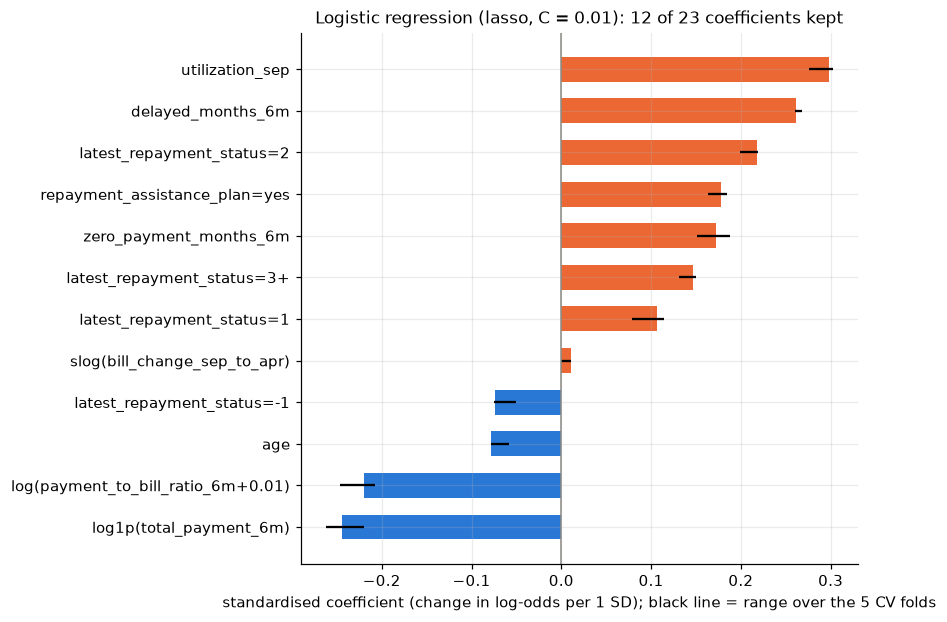

intercept (log-odds of an average client): -1.537 -> P(yes) = 0.177
dropped by the lasso: ['latest_repayment_status=-2', 'maximum_repayment_delay_6m', 'log(credit_limit)', 'slog(average_bill_6m)', 'sex=male', 'education=graduate_school', 'education=high_school', 'education=other', 'education=unknown', 'marital_status=married', 'marital_status=other_or_unknown']


,std coef,fold min,fold max,change,odds ratio,P(yes) average client,P(yes) after the change,change in P (points)
utilization_sep,0.299,0.276,0.302,+0.10 of the limit,1.077,0.177,0.188,1.102
delayed_months_6m,0.261,0.260,0.268,+1 month,1.183,0.177,0.203,2.586
log1p(total_payment_6m),-0.245,-0.262,-0.220,doubling the amount,0.932,0.177,0.167,-1.008
log(payment_to_bill_ratio_6m+0.01),-0.219,-0.246,-0.208,doubling the amount,0.897,0.177,0.162,-1.529
latest_repayment_status=2,0.218,0.199,0.219,vs reference level,2.155,0.177,0.317,13.973
repayment_assistance_plan=yes,0.178,0.164,0.185,vs reference level,1.546,0.177,0.249,7.247
zero_payment_months_6m,0.172,0.151,0.187,+1 month,1.105,0.177,0.192,1.502
latest_repayment_status=3+,0.147,0.131,0.150,vs reference level,3.295,0.177,0.415,23.772
latest_repayment_status=1,0.107,0.079,0.114,vs reference level,1.382,0.177,0.229,5.216
age,-0.078,-0.079,-0.058,+10 years,0.919,0.177,0.165,-1.194


,accuracy,roc_auc,balanced_acc,recall,f1,fit (s)
Logistic regression,0.8151 ± 0.0040,0.7605 ± 0.0072,0.6181 ± 0.0076,0.2761 ± 0.0140,0.3877 ± 0.0169,0.3


In [14]:
results["Logistic regression"], oof_probs["Logistic regression"], fold_models["Logistic regression"] = lr_cv[LR_C]
results["Logistic regression"].name = "Logistic regression"
lr = make_lr(LR_C).fit(X, y)
coef = pd.Series(lr[-1].coef_[0], index=lr[0].transform(X.head(1)).columns)
fold_coef = pd.DataFrame([pd.Series(m[-1].coef_[0], index=coef.index) for m, _ in fold_models["Logistic regression"]])

def natural_unit(c):
    """A change that is easy to say out loud, expressed in the units of the transformed column."""
    if "(" in c:
        return np.log(2), "doubling the amount"
    if c == "age":
        return 10, "+10 years"
    if c == "utilization_sep":
        return 0.1, "+0.10 of the limit"
    if c in ("maximum_repayment_delay_6m", "delayed_months_6m", "zero_payment_months_6m"):
        return 1, "+1 month"
    return 1, "vs reference level"


# odds ratio for that change, everything else fixed (coef / sd undoes the standardisation), and what it means in
# probability for a reference client: the average client (all z = 0, so its logit is the intercept)
sd = pd.Series(lr[1].scale_, index=coef.index)
kept = coef[coef != 0].sort_values()
shift = pd.Series({c: kept[c] / sd[c] * natural_unit(c)[0] for c in kept.index})  # change in log-odds
sigmoid = lambda z: 1 / (1 + np.exp(-z))
b0 = lr[-1].intercept_[0]
table = pd.DataFrame({"std coef": kept, "fold min": fold_coef[kept.index].min(), "fold max": fold_coef[kept.index].max(),
                      "change": [natural_unit(c)[1] for c in kept.index],
                      "odds ratio": np.exp(shift),
                      "P(yes) average client": sigmoid(b0),
                      "P(yes) after the change": sigmoid(b0 + shift),
                      "change in P (points)": 100 * (sigmoid(b0 + shift) - sigmoid(b0))})

fig, ax = plt.subplots(figsize=(8, 0.38 * len(kept) + 1.2))
ax.barh(kept.index, kept.values, color=[C_POS if v > 0 else C_NEG for v in kept.values], height=0.6)
ax.hlines(range(len(kept)), table["fold min"], table["fold max"], color="black", lw=1.5)
ax.axvline(0, color=C_REF, lw=1)
ax.set_xlabel("standardised coefficient (change in log-odds per 1 SD); black line = range over the 5 CV folds")
ax.set_title(f"Logistic regression (lasso, C = {LR_C}): {len(kept)} of {len(coef)} coefficients kept")
plt.tight_layout()
plt.show()
print(f"intercept (log-odds of an average client): {b0:.3f} -> P(yes) = {sigmoid(b0):.3f}")
print("dropped by the lasso:", list(coef[coef == 0].index))
display(table.sort_values("std coef", key=abs, ascending=False).round(3))
show_cv(results["Logistic regression"])

**Global interpretation.** The intercept (-1.54) is the log-odds of the **average client** (every variable at its mean, so all $z_j = 0$), which is a probability of difficulty of **17.7%**. Every coefficient moves the log-odds up or down from there. Since the model is linear in the log-odds, changing one input by $\Delta$ (in the units of the transformed column, which has standard deviation $s_j$) **multiplies the odds** by the same factor whatever the starting point:

$$\text{OR}_j \;=\; \frac{\text{odds}(x_j + \Delta)}{\text{odds}(x_j)} \;=\; \exp\!\Big(\frac{\beta_j}{s_j}\,\Delta\Big), \qquad \text{odds} = \frac{P}{1-P}$$

For a log-transformed variable, doubling the amount is $\Delta = \log 2$. Odds are not very intuitive, so the table also translates each effect into **probability for the average client**:

$$P_{\text{after}} \;=\; \sigma\Big(\beta_0 + \frac{\beta_j}{s_j}\,\Delta\Big), \qquad \sigma(t) = \frac{1}{1+e^{-t}}$$

The odds ratio is the general effect, valid for any client. The change in probability is only valid for the average client: the same odds ratio moves a client at 50% more points than one at 18%, and one at 3% fewer (that is how the sigmoid works). Read that way, starting from the average client at 17.7% and changing one thing at a time:

* **Being late right now dominates.** Compared with code 0, being 1 month late takes the probability to 22.9% (odds x1.38), 2 months to 31.7% (x2.16) and 3 or more to **41.5%** (x3.30), more than twice the starting point. Code -1 lowers it to 15.1% (x0.83).
* **Every extra month late** in the last six adds about 2.6 points (20.3%, odds x1.18). These effects stack: a client who is 3 months late now is usually also late in several of the six months, so the total effect of "being late" is split across correlated variables and one bar alone understates it.
* **Paying.** Doubling the share of the bill paid (more precisely, `ratio + 0.01`) takes the probability down to 16.2% (x0.90), and doubling the amount paid to 16.7% (x0.93). Both stay in the model because they say different things: paying a bigger part of the bill, and paying more money in absolute terms. Each extra month with no payment adds 1.5 points (19.2%, x1.10).
* **Utilisation.** Every 10 extra points of the limit used add about 1 point (18.8%, x1.08). Over a bigger range it adds up: a card at 100% has about 1.7 times the odds of one at 30%.
* **Assistance plan.** Having one raises the probability to 24.9% (x1.55). This is an association, not an effect: the plan is offered to clients who already show signs of stress, so it marks clients in trouble.
* **Age** is the only demographic variable left, and it is weak (10 more years: 16.5%, x0.92). The bill change is kept but its effect is negligible.

The black lines show the coefficients of the 5 fold models. They are stable: no sign changes, and the size moves by a few hundredths. The bar is the fit on all 25,000 clients, so it doesn't have to fall inside the fold range. Two caveats for reading these numbers. They are **conditional** ("with everything else fixed", which is rarely realistic with correlated variables), and the lasso **shrinks** them, so the effects are on the conservative side.

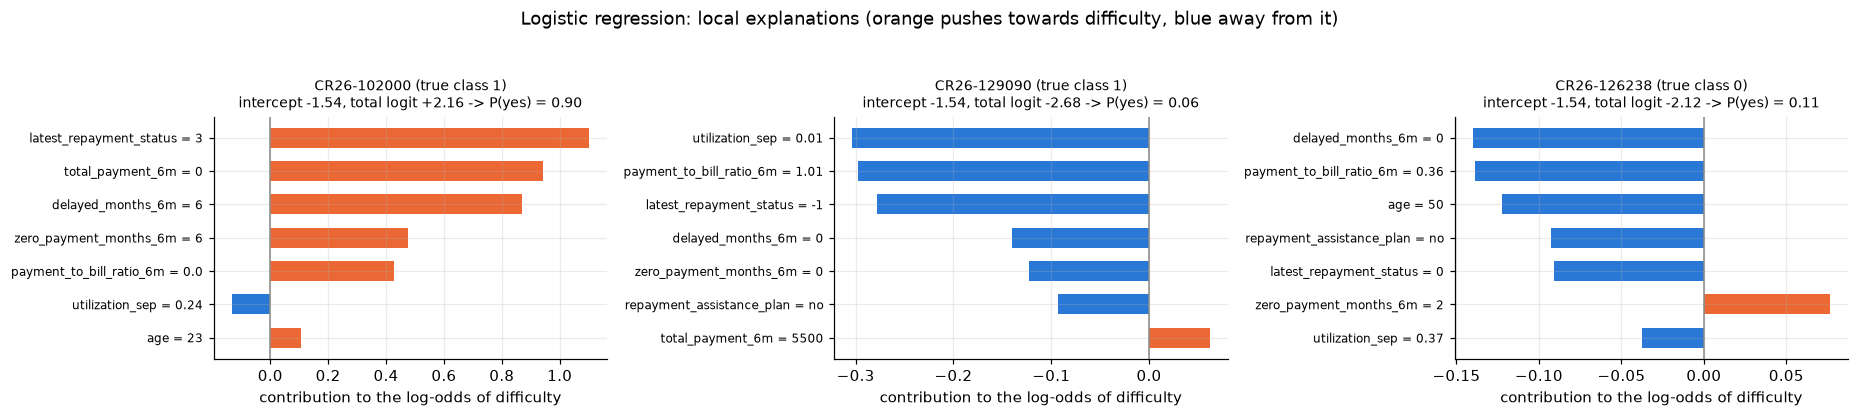

In [15]:
def plot_local(ax, contrib, base, x_row, title, k=7):
    """Bar chart of the k largest contributions (log-odds) of one client, labelled with the client's raw values."""
    logit = base + contrib.sum()
    c = contrib[contrib.abs() > 1e-6]
    c = c.reindex(c.abs().sort_values().index[-k:])
    labels = [f"{f} = {x_row[f]}" for f in c.index]
    ax.barh(labels, c.values, color=[C_POS if v > 0 else C_NEG for v in c.values], height=0.6)
    ax.axvline(0, color=C_REF, lw=1)
    ax.set_title(f"{title}\nintercept {base:+.2f}, total logit {logit:+.2f} -> P(yes) = {1 / (1 + np.exp(-logit)):.2f}", fontsize=9)
    ax.tick_params(axis="y", labelsize=8)
    ax.set_xlabel("contribution to the log-odds of difficulty")


def lr_contributions(model, rows):
    """Per-feature log-odds contributions coef_j * z_j, summed back to the raw variables. They add up to logit - intercept."""
    F = model[0].transform(rows)
    contrib = pd.DataFrame(model[1].transform(F) * model[-1].coef_[0], columns=F.columns, index=rows.index)
    return contrib.T.groupby(raw_name).sum().T, model[-1].intercept_[0]


fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, i in zip(axes, LOCAL_IDX):
    contrib, base = lr_contributions(lr, X.loc[[i]])
    plot_local(ax, contrib.loc[i], base, X.loc[i], f"{train.row_id[i]} (true class {y[i]})")
fig.suptitle("Logistic regression: local explanations (orange pushes towards difficulty, blue away from it)", y=1.04)
plt.tight_layout()
plt.show()

**Local interpretation.** For one client the logit splits exactly into one term per variable:

$$\text{logit}\,P(\text{yes} \mid x) \;=\; \beta_0 + \sum_{j} \underbrace{\beta_j z_j}_{\text{bar } j}$$

Since $z_j = 0$ is the average client, each bar says how much that variable moves this client away from an average one, and the bars plus the intercept add up to the logit (the categories of one variable, such as the status codes, are summed into a single bar). Unlike the tree, the logistic regression always weighs all the evidence:

* **CR26-102000** (P = 0.90): every behavioural variable points the same way. 3 months late now (+1.10), paid nothing in absolute terms (+0.94), late in all six months (+0.87), six months without paying (+0.47) and nothing paid relative to the bill (+0.42). Age, which decided the tree's path, only adds +0.10 here.
* **CR26-129090** (P = 0.06): everything pushes towards "no". The card is almost empty (utilisation 0.01), it paid 101% of its bill and the status is -1. Only the small absolute payment (5,500) pushes up a little. The model is confidently wrong, for the same reason as the tree.
* **CR26-126238** (P = 0.11): no delays, a decent payment ratio (0.36) and age 50 push it down, with a small push up from 2 months without payment (+0.08). The logistic regression gives this real negative a *higher* risk than the real positive above.

## 5. Model family 3: Explainable Boosting Machine

An EBM is a generalised additive model: the log-odds is the intercept plus one function per variable, $\text{logit}\,P(\text{yes}) = \beta_0 + \sum_j f_j(x_j)$. Each $f_j$ is learned by boosting very shallow trees on one variable at a time in round robin, so it can take any shape (thresholds, plateaus, reversals) while the model stays as readable as a logistic regression: one plot per variable. With `interactions=0` there are no pairwise terms, so that plot is all there is to know about each variable.

It needs no preprocessing: numeric variables are binned internally (up to 1024 bins) and categorical ones are handled natively. We keep the default settings. They already include 14 outer bags (the model is fitted on 14 subsamples and averaged), which gives smoother shapes and an uncertainty band for each of them, and our goal is not to squeeze accuracy. The only thing we check with the CV is how much we lose by forbidding interactions.

In [16]:
EBM_PARAMS = {"interactions": 0, "random_state": SEED}
n_terms = lambda m: len(m.term_names_)
results["EBM"], oof_probs["EBM"], fold_models["EBM"] = cv_evaluate(
    lambda: ExplainableBoostingClassifier(**EBM_PARAMS), X, y, "EBM", size=n_terms)
# only to check how much the additivity assumption costs; this model is not interpreted
ebm_int, _, _ = cv_evaluate(lambda: ExplainableBoostingClassifier(interactions=10, random_state=SEED), X, y,
                            "EBM with 10 pairwise interactions", size=n_terms)
show_cv(results["EBM"], ebm_int)

,accuracy,roc_auc,balanced_acc,recall,f1,fit (s)
EBM,0.8188 ± 0.0023,0.7760 ± 0.0057,0.6290 ± 0.0020,0.2993 ± 0.0022,0.4121 ± 0.0043,11.2
EBM with 10 pairwise interactions,0.8191 ± 0.0024,0.7758 ± 0.0055,0.6301 ± 0.0021,0.3019 ± 0.0019,0.4145 ± 0.0045,25.4


The EBM gets **0.8188 ± 0.0023** in accuracy and **0.776** in AUC, the best of the three families on every metric, and even slightly above the Phase I gradient boosting black box (0.8164, AUC 0.768). Adding 10 pairwise interactions changes nothing (0.8191, same AUC), so the additive structure already captures what the data has to offer. That justifies `interactions=0`, which keeps each variable explainable with a single curve.

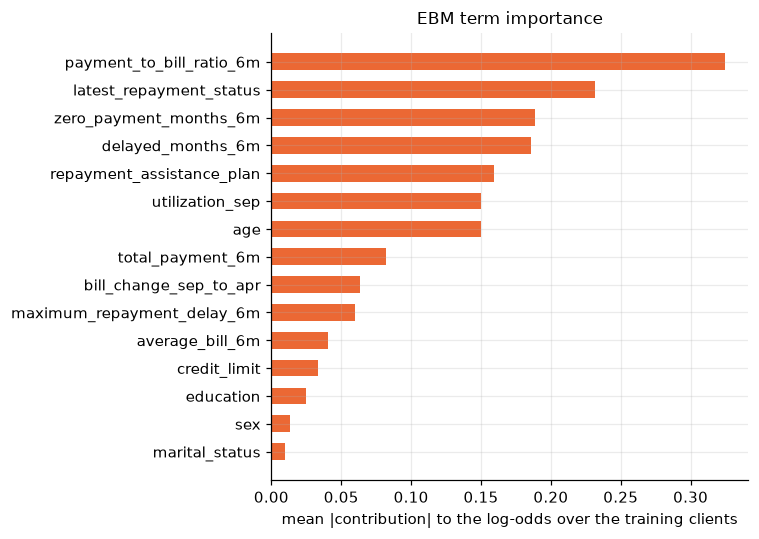

intercept: -1.578


In [17]:
ebm = ExplainableBoostingClassifier(**EBM_PARAMS).fit(X, y)
imp = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values, color=C_MODEL["EBM"], height=0.6)
ax.set_xlabel("mean |contribution| to the log-odds over the training clients")
ax.set_title("EBM term importance")
plt.tight_layout()
plt.show()
print(f"intercept: {ebm.intercept_[0]:.3f}")

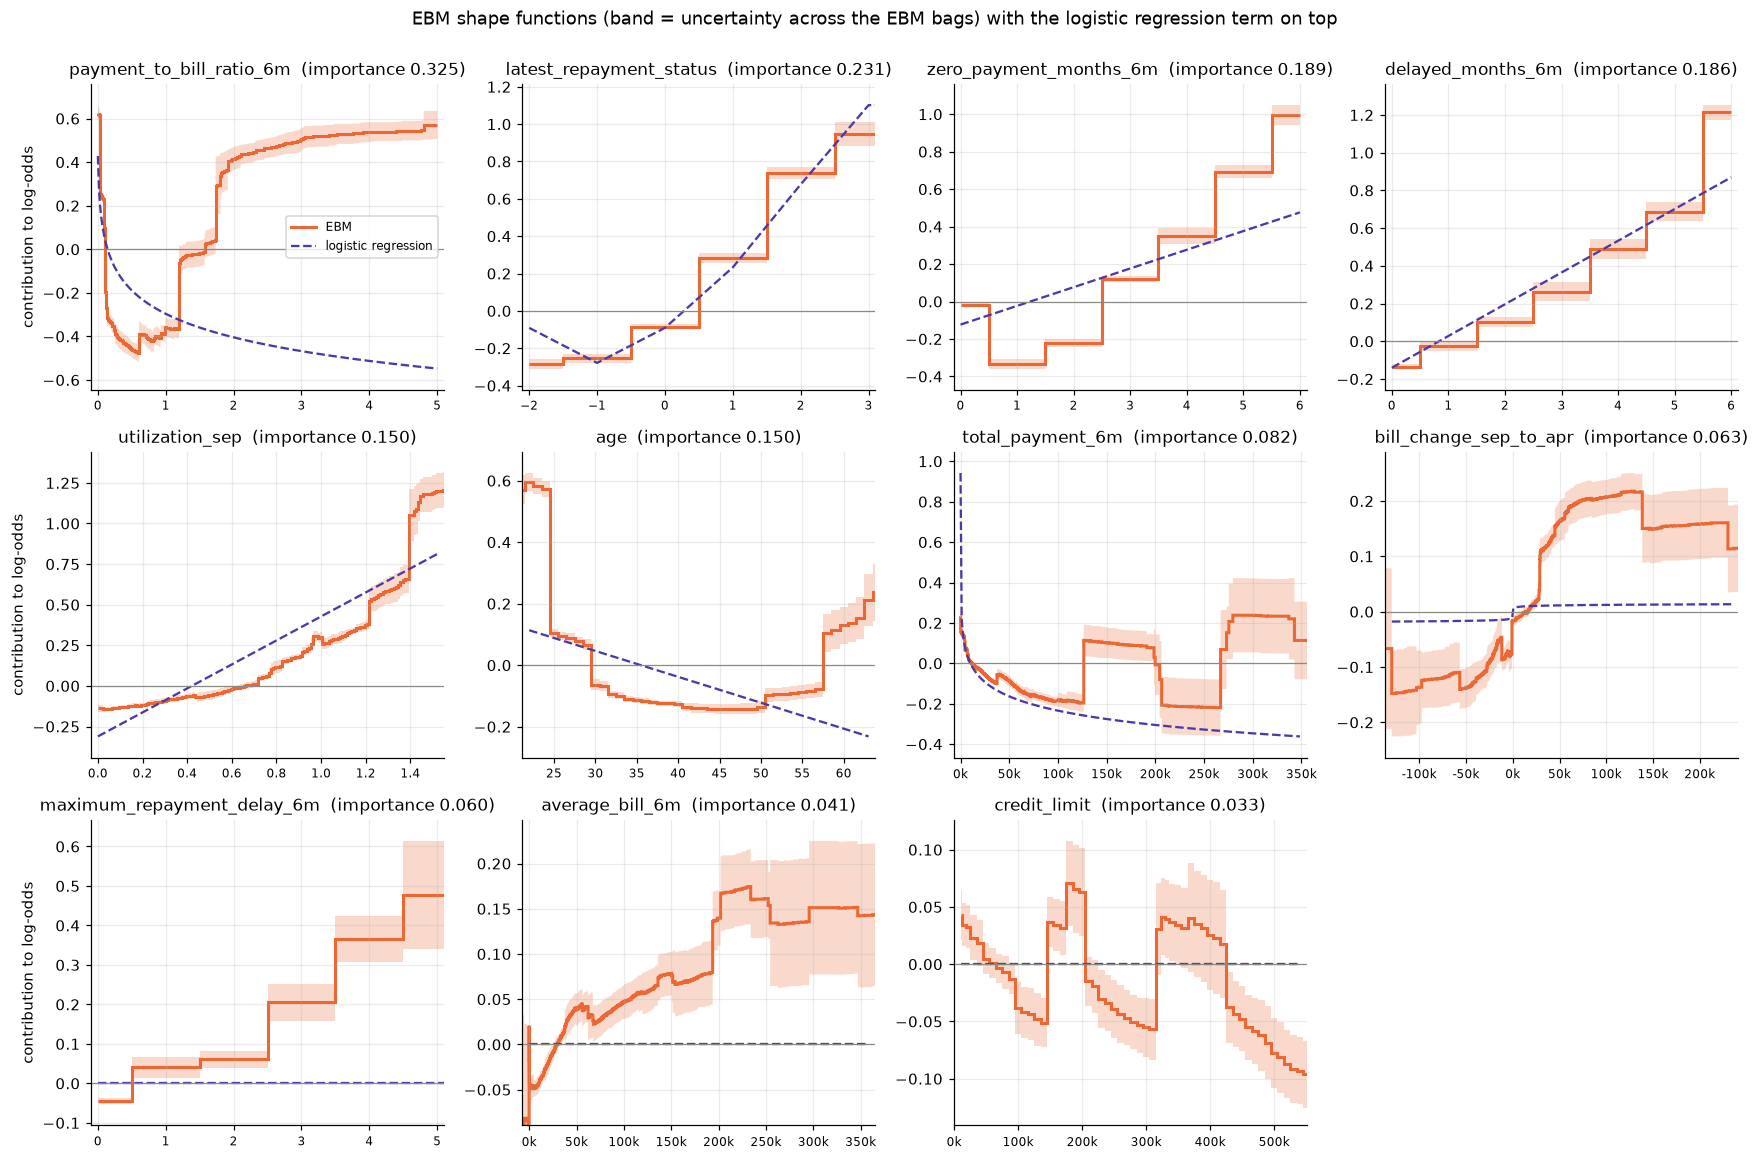

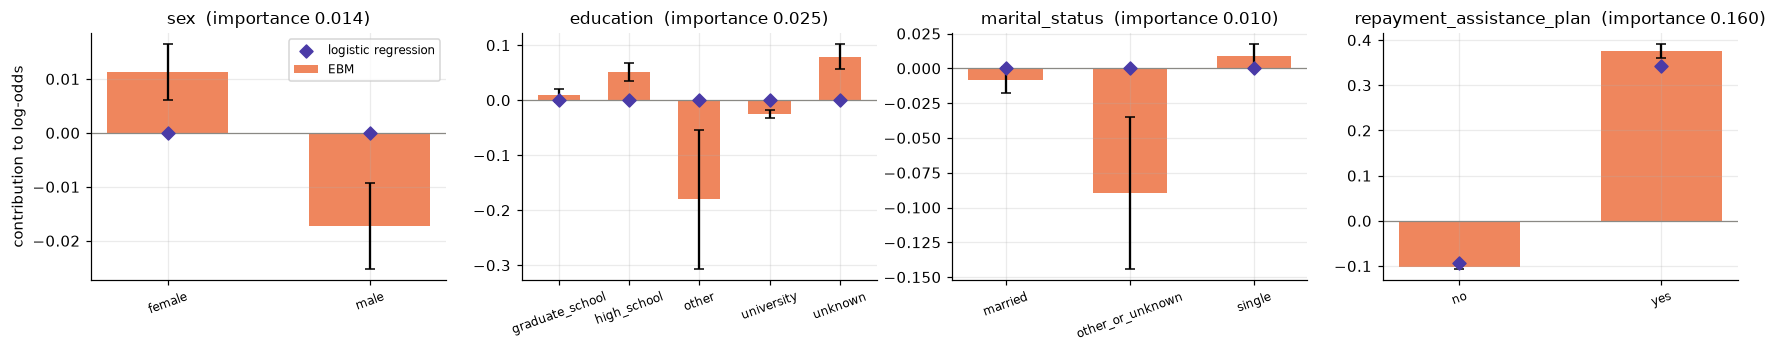

In [18]:
def lr_curve(model, feature, xs):
    """Contribution of one raw variable in the logistic regression, centred like the EBM shapes (mean 0 on train)."""
    rows = X.iloc[[0] * len(xs)].reset_index(drop=True)
    rows[feature] = xs
    contrib, _ = lr_contributions(model, rows)
    return contrib[feature].to_numpy() if feature in contrib else np.zeros(len(xs))


ebm_global = ebm.explain_global()
shape = {name: ebm_global.data(i) for i, name in enumerate(ebm.term_names_)}
num_feats = [f for f in imp.index[::-1] if f not in CAT_COLS]

fig, axes = plt.subplots(3, 4, figsize=(16, 10.5))
for ax, f in zip(axes.flat, num_feats):
    d = shape[f]
    edges, s = np.asarray(d["names"], dtype=float), d["scores"]
    lo, hi = X[f].quantile([0.005, 0.995])  # long tails: show the central 99% of the clients
    ax.stairs(d["upper_bounds"], edges, baseline=d["lower_bounds"], fill=True, color=C_MODEL["EBM"], alpha=0.25)
    ax.stairs(s, edges, baseline=None, color=C_MODEL["EBM"], lw=2, label="EBM")
    xs = np.unique(X[f]) if X[f].nunique() <= 12 else np.linspace(lo, hi, 300)
    lr_y = lr_curve(lr, f, xs)
    ax.plot(xs, lr_y, color=C_MODEL["Logistic regression"], ls="--", lw=1.5, label="logistic regression")
    ax.axhline(0, color=C_REF, lw=0.8)
    ax.set_xlim(lo - 0.02 * (hi - lo), hi + 0.02 * (hi - lo))
    visible = (edges[:-1] <= hi) & (edges[1:] >= lo)  # y range from the bins on screen only
    y_lo, y_hi = min(d["lower_bounds"][visible].min(), lr_y.min()), max(d["upper_bounds"][visible].max(), lr_y.max())
    ax.set_ylim(y_lo - 0.08 * (y_hi - y_lo), y_hi + 0.08 * (y_hi - y_lo))
    if X[f].abs().max() > 10000:  # money in thousands of NTD
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
    ax.set_title(f"{f}  (importance {imp[f]:.3f})")
    ax.tick_params(axis="x", labelsize=8)
axes[0, 0].legend(fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("contribution to log-odds")
for ax in axes.flat[len(num_feats):]:
    ax.axis("off")
fig.suptitle("EBM shape functions (band = uncertainty across the EBM bags) with the logistic regression term on top", y=1.0)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.3))
for ax, f in zip(axes, CAT_COLS):
    d = shape[f]
    pos = np.arange(len(d["names"]))
    ax.bar(pos, d["scores"], yerr=[d["scores"] - d["lower_bounds"], d["upper_bounds"] - d["scores"]],
           color=C_MODEL["EBM"], alpha=0.8, width=0.6, capsize=3, label="EBM")
    ax.scatter(pos, lr_curve(lr, f, d["names"]), color=C_MODEL["Logistic regression"], marker="D", zorder=3, label="logistic regression")
    ax.set_xticks(pos, d["names"], rotation=20, fontsize=8)
    ax.axhline(0, color=C_REF, lw=0.8)
    ax.set_title(f"{f}  (importance {imp[f]:.3f})")
axes[0].set_ylabel("contribution to log-odds")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Before reading the shapes, a sanity check on the two that surprised us most (the rise of the payment ratio curve on the right, and age): are they also visible in the raw data, or are they artefacts of the model?

In [19]:
# do the two most surprising shapes also show up in the raw difficulty rates?
ratio_bins = pd.cut(X.payment_to_bill_ratio_6m, [-0.01, 0, 0.03, 0.1, 0.35, 1, 1.2, 1.75, 3, 5])
display(train.groupby(ratio_bins, observed=True)
        .agg(clients=(TARGET, "size"), difficulty_rate=(TARGET, "mean"), median_average_bill=("average_bill_6m", "median"))
        .round(3).T)
age_bins = pd.cut(X.age, [20, 24, 29, 40, 50, 57, 80])
display(train.groupby(age_bins, observed=True)[TARGET].agg(clients="size", difficulty_rate="mean").round(3).T)

payment_to_bill_ratio_6m,"(-0.01, 0.0]","(0.0, 0.03]","(0.03, 0.1]","(0.1, 0.35]","(0.35, 1.0]","(1.0, 1.2]","(1.2, 1.75]","(1.75, 3.0]","(3.0, 5.0]"
clients,1230.000,2082.000,9841.000,3741.000,5778.000,1185.000,638.000,286.000,219.00
difficulty_rate,0.576,0.377,0.261,0.127,0.085,0.076,0.116,0.185,0.26
median_average_bill,0.000,68150.000,44700.000,20300.000,4400.000,3700.000,2300.000,1100.000,400.00


age,"(20, 24]","(24, 29]","(29, 40]","(40, 50]","(50, 57]","(57, 80]"
clients,2247.000,5777.000,10055.000,5007.000,1458.000,456.000
difficulty_rate,0.343,0.222,0.185,0.187,0.219,0.298


They are in the data. The difficulty rate drops from 58% (ratio 0) to 7.6% (ratio 1.0 to 1.2) and then **goes back up to 18.5%, 27% and 25%** for ratios above 1.75. Those clients have tiny bills (median 300 to 1,100 NTD). Age shows a U: 34% up to 24 years old, 18.5% between 30 and 50, and 30% above 57.

**Global interpretation.** Each curve is the contribution of the variable to the log-odds (0 = the average client). Since there are no interactions, the curve is the same whatever the other variables are. The dashed line is the same term in the logistic regression, so we can see directly where the linear assumption holds and where it breaks.

* **`payment_to_bill_ratio_6m`** (the most important). The left part matches the logistic regression: paying nothing adds +0.6, and the risk drops fast until about 0.5, where the curve bottoms out (-0.45). Then the EBM finds a **reversal**: steps at about 1.2 and 1.75 take the contribution up to +0.4/+0.55. Paying more than 1.75 times the bills is about as bad as paying 1%. The data dictionary gives the explanation: very large ratios come from large catch-up payments or very small recorded bills, so someone who has just paid off a big lump of old debt has recently been in trouble. It is only 2% of the clients, but the logistic regression gets it **backwards**: with its log, those are its safest clients. CART in Phase I also cut at 1.735, which confirms it independently.
* **`latest_repayment_status`**. Codes -2 and -1 are at the same level (-0.27), 0 slightly below average, and then a staircase: +0.28 at 1 month late, +0.75 at 2 and +0.95 at 3 or more. The big jump is when the client is actually late. Once the other variables are accounted for, the EBM treats -2 like -1 (both safer than 0), while the logistic regression treats -2 like 0. It is a minor disagreement, on a code whose meaning we don't know anyway.
* **`delayed_months_6m`**. Almost linear from 0 to 5 months, where the logistic regression fits well, then a **jump at 6** (+1.2 instead of the +0.7 a straight line would give). Being late *every* month is a different profile, and it is the same cut GOSDT uses (`delayed_months_6m >= 6`).
* **`zero_payment_months_6m`**. Not monotonic. 1 or 2 months without paying is *safer* than 0 (-0.3/-0.2), and the risk then grows up to **+1.0 at 6 months**. Clients who pay every month are typically revolving large balances (median bill 38k, median payment ratio 0.08), while skipping one or two payments goes with smaller bills. Six months without paying is mostly inactive cards (median bill 0) that still have 57% difficulty. The EBM spreads that profile over three related curves: for the 844 clients with an average bill of exactly 0 (51% difficulty), it adds on average +0.93 from this curve, +0.54 from a payment ratio of 0 and +0.22 from a total payment of 0. The linear term underestimates the jump at 6 and puts 1 and 2 on the wrong side.
* **`utilization_sep`**. Close to linear between 0 and 1.2, where the two models agree, then a jump at 1.4 (more than 40% over the limit) to +1.2. Only 266 clients are above 1.2.
* **`age`**. The **U shape**: +0.6 under 25, a big drop at 25 and another at 30, flat between 30 and 57, and rising again after 57 (with a wider band, there are few older clients). The logistic regression's single slope misses both ends and calls the oldest clients the safest. The drop at 25 is exactly GOSDT's root split: two very different learners place the same threshold.
* **`repayment_assistance_plan`**. "Yes" adds +0.37 against -0.10 for "no", close to the logistic regression. As before, this is selection, not an effect of the plan.
* **Second tier.** `total_payment_6m` matters near 0 (paying nothing at all), and beyond that the steps are based on few clients with wide bands, so we don't read them. A **growing bill** since April adds up to +0.2 and a shrinking one -0.13 (`bill_change_sep_to_apr`, dropped by the lasso). `maximum_repayment_delay_6m` rises steadily but is mostly redundant with the other delay variables. `average_bill_6m` and `credit_limit` are nearly flat.
* **Demographics.** Sex contributes ±0.015, practically nothing. The education "other" and marital status "other_or_unknown" bars have huge error bars because they have 109 and 322 clients: that is noise, not a finding.

Overall, where the two curves overlap (delays, status, utilisation in its normal range, the plan), the logistic regression is a good summary. Where they diverge (the payment ratio tail, both ends of age, the months without payment, six delayed months), the EBM shows the thresholds and reversals the data dictionary warned us about.

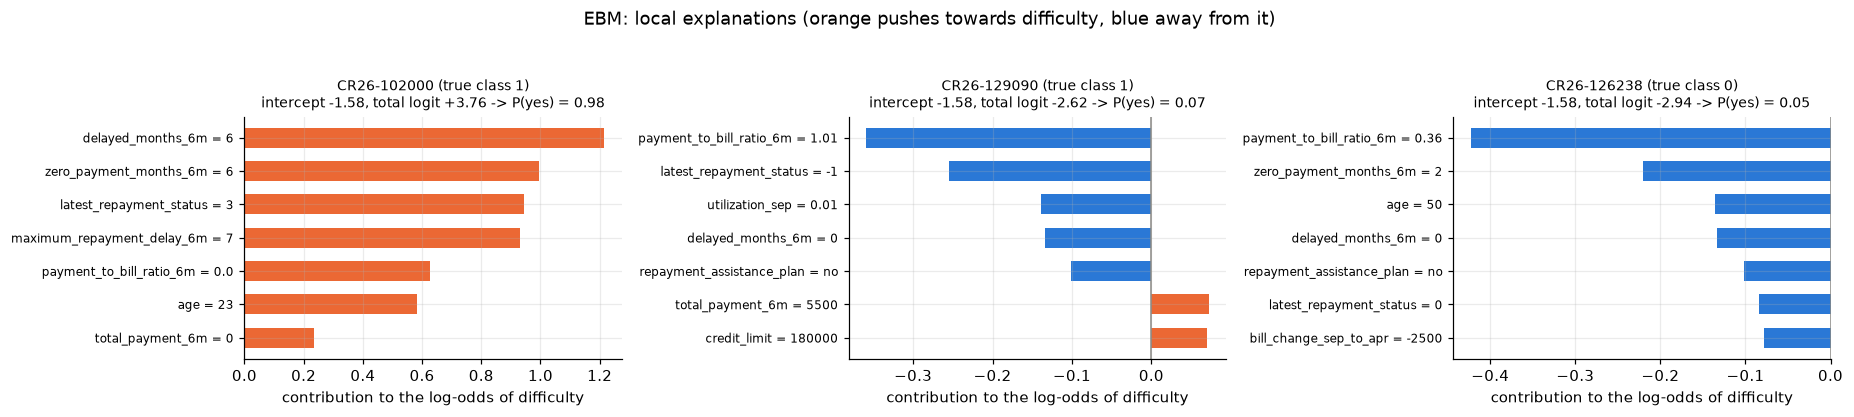

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, i in zip(axes, LOCAL_IDX):
    contrib = pd.Series(ebm.eval_terms(X.loc[[i]])[0], index=ebm.term_names_)
    plot_local(ax, contrib, ebm.intercept_[0], X.loc[i], f"{train.row_id[i]} (true class {y[i]})")
fig.suptitle("EBM: local explanations (orange pushes towards difficulty, blue away from it)", y=1.04)
plt.tight_layout()
plt.show()

**Local interpretation.** Same reading as for the logistic regression (bars plus intercept = logit), but each bar now comes from the curves above:

* **CR26-102000** (P = 0.98, against 0.90 for the logistic regression). Late in all six months (+1.21), six months without paying (+1.00), 3 months late now (+0.95), a maximum delay of 7 (+0.93), nothing paid (+0.63) and age 23 (+0.58). The EBM is more extreme because it picks up the jumps at 6 months that a straight line flattens, plus the young age the logistic regression barely uses. This explanation contains both the tree's reason (young, late, paying little) and the logistic regression's (delays).
* **CR26-129090** (P = 0.07, the same as the logistic regression). It paid 101% of the bill (-0.36) and has status -1 and an empty card. Again, nothing in the data says this client is at risk.
* **CR26-126238** (P = 0.05, against 0.11). A payment ratio of 0.36 is close to the bottom of the curve (-0.42). **Two months without payment counts as -0.22 here, while the logistic regression gave it +0.08**: the same fact about the same client gets opposite signs, simply because one model forces that variable to be linear. Age 50 also helps (-0.14).

## 6. Comparing the three models

### 6.1 Summary table and classification threshold

In [21]:
MODELS = ["GOSDT", "Logistic regression", "EBM"]
size_txt = {"GOSDT": f"{gosdt.n_leaves()} leaves", "Logistic regression": f"{(lr[-1].coef_ != 0).sum()} non zero coefficients",
            "EBM": f"{len(ebm.term_names_)} shape functions"}
settings = {"Majority baseline": ("DummyClassifier", "strategy='most_frequent'"),
            "GOSDT": ("GOSDT (optimal sparse decision tree)", f"depth_budget={GOSDT_PARAMS['depth_budget']}, regularization={GOSDT_PARAMS['regularization']}, 25 hand-made binary features"),
            "Logistic regression": ("LogisticRegression", f"lasso (L1), C={LR_C}, standardised, status as category, logs of money variables"),
            "EBM": ("ExplainableBoostingClassifier", "interactions=0, rest default")}
summary = show_cv(*[results[k] for k in ["Majority baseline"] + MODELS])
summary.insert(0, "size", ["1 constant"] + [size_txt[k] for k in MODELS])
summary.insert(0, "key settings", [settings[k][1] for k in summary.index])
summary.insert(0, "classifier", [settings[k][0] for k in summary.index])
summary

,classifier,key settings,size,accuracy,roc_auc,balanced_acc,recall,f1,fit (s)
Majority baseline,DummyClassifier,strategy='most_frequent',1 constant,0.7879 ± 0.0001,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0
GOSDT,GOSDT (optimal sparse decision tree),"depth_budget=4, regularization=0.0005, 25 hand...",7 leaves,0.8154 ± 0.0020,0.6494 ± 0.0082,0.6132 ± 0.0030,0.2619 ± 0.0054,0.3758 ± 0.0068,2.3
Logistic regression,LogisticRegression,"lasso (L1), C=0.01, standardised, status as ca...",12 non zero coefficients,0.8151 ± 0.0040,0.7605 ± 0.0072,0.6181 ± 0.0076,0.2761 ± 0.0140,0.3877 ± 0.0169,0.3
EBM,ExplainableBoostingClassifier,"interactions=0, rest default",15 shape functions,0.8188 ± 0.0023,0.7760 ± 0.0057,0.6290 ± 0.0020,0.2993 ± 0.0022,0.4121 ± 0.0043,11.2


GOSDT                accuracy at 0.5 = 0.8154 | best threshold 0.44 -> 0.8154


Logistic regression  accuracy at 0.5 = 0.8151 | best threshold 0.49 -> 0.8153


EBM                  accuracy at 0.5 = 0.8188 | best threshold 0.48 -> 0.8195


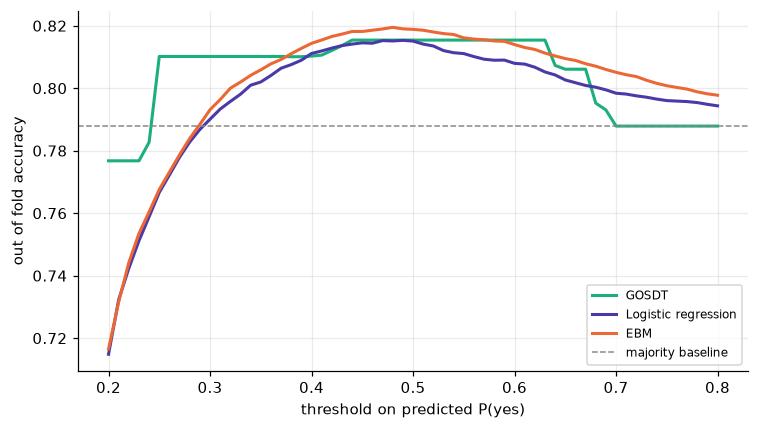

In [22]:
ths = np.linspace(0.2, 0.8, 61)
THRESHOLD = {k: 0.5 for k in MODELS}  # kept after looking at these curves (see below)
fig, ax = plt.subplots(figsize=(7, 4))
for k in MODELS:
    accs = np.array([accuracy_score(y, oof_probs[k] >= t) for t in ths])
    acc_05 = accuracy_score(y, oof_probs[k] >= 0.5)
    ax.plot(ths, accs, lw=2, color=C_MODEL[k], label=k)
    print(f"{k:20s} accuracy at 0.5 = {acc_05:.4f} | best threshold {ths[accs.argmax()]:.2f} -> {accs.max():.4f}")
ax.axhline(1 - y.mean(), color=C_REF, ls="--", lw=1, label="majority baseline")
ax.set_xlabel("threshold on predicted P(yes)")
ax.set_ylabel("out of fold accuracy")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The **EBM is the best on every metric** (accuracy 0.8188, AUC 0.776, recall 0.30, F1 0.41). GOSDT and the logistic regression are tied in accuracy (0.8154 and 0.8151), but the logistic regression ranks clients much better (AUC 0.761 against 0.649), because it gives a continuous score instead of 7 values. The accuracy differences between the three models are small (0.4 points between the best and the worst, around one or two fold standard deviations), so for an accuracy task the price of the simplest model is low. The difference is clearer in ranking.

**Recall.** All three models miss most of the clients with difficulty: they catch between 26% (GOSDT) and 30% (EBM) of them, with the logistic regression in between (28%). This is a consequence of optimising accuracy with 21% positives: at the 0.5 threshold a model only says "yes" when difficulty is more likely than not, and few clients reach that point. If the goal were to detect as many clients in trouble as possible, we would lower the threshold, at the cost of accuracy.

**Threshold.** The best out of fold thresholds are between 0.44 and 0.49, and they improve accuracy by 0.0007 at most, much less than the variation between folds, so moving the threshold would mostly fit noise. We keep 0.5 for the three models, which is also the natural threshold for accuracy when the probabilities are reasonably calibrated.

### 6.2 What does each model use?

The three models express importance in different units (path, coefficient, curve), so to compare them we use one model-agnostic measure: how much the CV AUC drops when one variable is shuffled. Shuffling a raw variable moves everything derived from it (for example, all the status categories of the logistic regression).

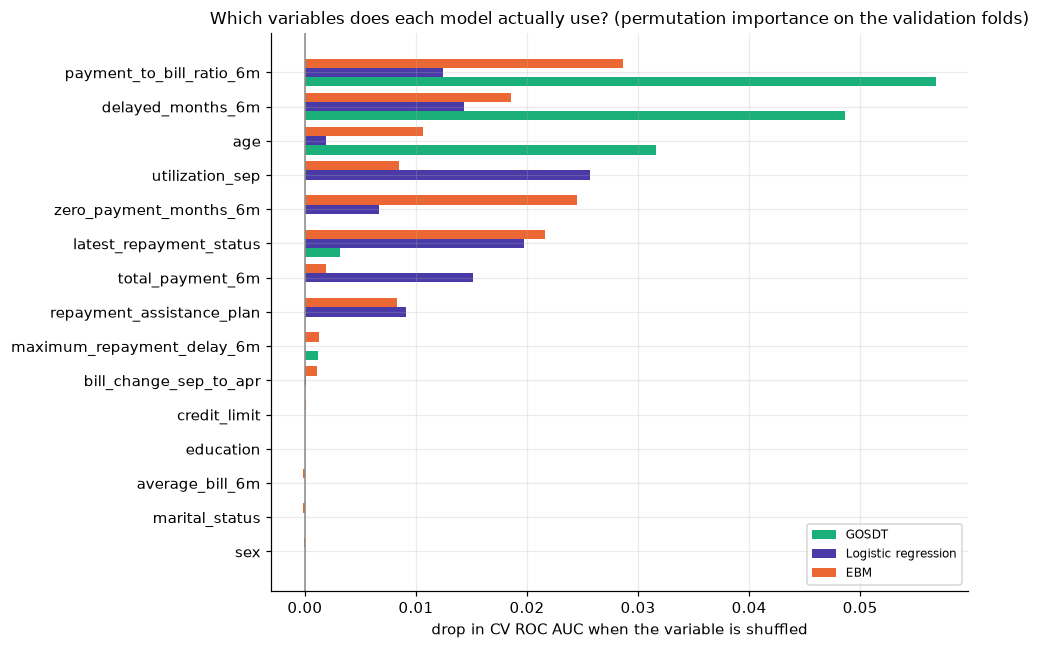

,GOSDT,Logistic regression,EBM
payment_to_bill_ratio_6m,0.0569,0.0124,0.0287
delayed_months_6m,0.0486,0.0143,0.0185
age,0.0316,0.0019,0.0107
utilization_sep,0.0000,0.0256,0.0085
zero_payment_months_6m,0.0000,0.0067,0.0245
latest_repayment_status,0.0032,0.0198,0.0216
total_payment_6m,0.0000,0.0151,0.0019
repayment_assistance_plan,0.0000,0.0091,0.0083
maximum_repayment_delay_6m,0.0011,0.0000,0.0013
bill_change_sep_to_apr,0.0000,0.0001,0.0011


In [23]:
def permutation_auc_drop(model, Xv, yv, rng, n_repeats=3):
    """Drop in AUC when one raw variable is shuffled (all the columns derived from it change together)."""
    base = roc_auc_score(yv, model.predict_proba(Xv)[:, 1])
    drops = {}
    for col in Xv.columns:
        d = []
        for _ in range(n_repeats):
            Xp = Xv.copy()
            Xp[col] = rng.permutation(Xp[col].to_numpy())
            d.append(base - roc_auc_score(yv, model.predict_proba(Xp)[:, 1]))
        drops[col] = np.mean(d)
    return pd.Series(drops)


# computed on the validation fold of each CV split, so it measures what the models use on unseen clients
rng = np.random.RandomState(SEED)
perm = pd.DataFrame({k: pd.concat([permutation_auc_drop(m, X.iloc[va], y.iloc[va], rng) for m, va in fold_models[k]], axis=1).mean(axis=1)
                     for k in MODELS})
perm = perm.loc[perm.max(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 6))
h = 0.27
for j, k in enumerate(MODELS):
    ax.barh(np.arange(len(perm)) + (j - 1) * h, perm[k], height=h, color=C_MODEL[k], label=k)
ax.set_yticks(np.arange(len(perm)), perm.index)
ax.axvline(0, color=C_REF, lw=1)
ax.set_xlabel("drop in CV ROC AUC when the variable is shuffled")
ax.set_title("Which variables does each model actually use? (permutation importance on the validation folds)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
perm.iloc[::-1].round(4)

* **Same core.** For all three models the payment ratio, the number of delayed months and the current status are among the most used variables. Demographics (except age), the credit limit and the bills are close to 0 everywhere, and sex is not used by any of them.
* **Age plays a very different role in each model.** It is GOSDT's third variable (0.032, the root split), it is moderately used by the EBM (0.011, mostly to flag the under 25s) and practically unused by the logistic regression (0.002), because a straight line can't use a U: the two ends cancel out.
* **Redundant variables are shared out differently.** Utilisation is the logistic regression's most important variable (0.026) and the payment ratio is the EBM's. The months without payment matter for the EBM (0.025, its jump at 6) and are not used by GOSDT at all. These variables overlap a lot, so each model takes the information from wherever its form makes it easiest. That is why "importance" has to be read as "importance *for this model*", not as a property of the variable.

### 6.3 Local explanations side by side, and a conflict

First, how often do the three final models agree on the training clients? From the most common disagreement we draw (with the seed) a fourth client to explain in all three models.

In [24]:
FITTED = {"GOSDT": gosdt, "Logistic regression": lr, "EBM": ebm}
classify = lambda k, rows: (FITTED[k].predict_proba(rows)[:, 1] >= THRESHOLD[k]).astype(int)

# agreement of the three final models on the training clients
pred = pd.DataFrame({k: classify(k, X) for k in MODELS}, index=X.index)
patterns = pred.value_counts().rename("clients").to_frame()
same = lambda df, p: (df == pd.Series(p, index=df.columns)).all(axis=1)
patterns["actual difficulty rate"] = [y[same(pred, p)].mean() for p in patterns.index]
display(patterns.round(3))

# extra local instance: a client from the most common disagreement pattern, drawn with the seed
disagree = pred[pred.nunique(axis=1) > 1]
top_pattern = disagree.value_counts().index[0]
EXTRA_IDX = np.random.RandomState(SEED).choice(disagree.index[same(disagree, top_pattern)])
ALL_LOCAL = LOCAL_IDX + [EXTRA_IDX]
print("extra instance:", train.row_id[EXTRA_IDX], "| pattern (GOSDT, LR, EBM):", tuple(int(v) for v in top_pattern))
display(train.loc[[EXTRA_IDX]].set_index("row_id").T)

clients  actual difficulty rate
GOSDT Logistic regression EBM                                 
0     0                   0      22076                   0.157
1     1                   1       1624                   0.704
0     1                   1        378                   0.571
                          0        269                   0.424
1     0                   0        226                   0.438
                          1        223                   0.619
0     0                   1        187                   0.599
1     1                   0         17                   0.529

extra instance: CR26-112045 | pattern (GOSDT, LR, EBM): (0, 1, 1)


row_id,CR26-112045
credit_limit,210000
sex,male
education,university
marital_status,single
age,31
latest_repayment_status,2
maximum_repayment_delay_6m,2
delayed_months_6m,3
average_bill_6m,160000
bill_change_sep_to_apr,71500


=== CR26-102000 | true class: 1 ===


,P(yes),prediction,main reasons
GOSDT,0.688,1,age < 25 and latest_repayment_status >= 1 and payment_to_bill_ratio_6m < 0.1
Logistic regression,0.896,1,"latest_repayment_status (+1.10), total_payment_6m (+0.94), delayed_months_6m (+0.87)"
EBM,0.977,1,"delayed_months_6m (+1.21), zero_payment_months_6m (+1.00), latest_repayment_status (+0.95)"


=== CR26-129090 | true class: 1 ===


,P(yes),prediction,main reasons
GOSDT,0.155,0,age >= 25 and payment_to_bill_ratio_6m >= 0.03 and delayed_months_6m < 6
Logistic regression,0.064,0,"utilization_sep (-0.30), payment_to_bill_ratio_6m (-0.30), latest_repayment_status (-0.28)"
EBM,0.068,0,"payment_to_bill_ratio_6m (-0.36), latest_repayment_status (-0.25), utilization_sep (-0.14)"


=== CR26-126238 | true class: 0 ===


,P(yes),prediction,main reasons
GOSDT,0.155,0,age >= 25 and payment_to_bill_ratio_6m >= 0.03 and delayed_months_6m < 6
Logistic regression,0.107,0,"delayed_months_6m (-0.14), payment_to_bill_ratio_6m (-0.14), age (-0.12)"
EBM,0.050,0,"payment_to_bill_ratio_6m (-0.42), zero_payment_months_6m (-0.22), age (-0.14)"


=== CR26-112045 | true class: 0 ===


,P(yes),prediction,main reasons
GOSDT,0.155,0,age >= 25 and payment_to_bill_ratio_6m >= 0.03 and delayed_months_6m < 6
Logistic regression,0.594,1,"latest_repayment_status (+0.68), utilization_sep (+0.39), delayed_months_6m (+0.36)"
EBM,0.532,1,"latest_repayment_status (+0.74), repayment_assistance_plan (+0.37), zero_payment_months_6m (-0.33)"


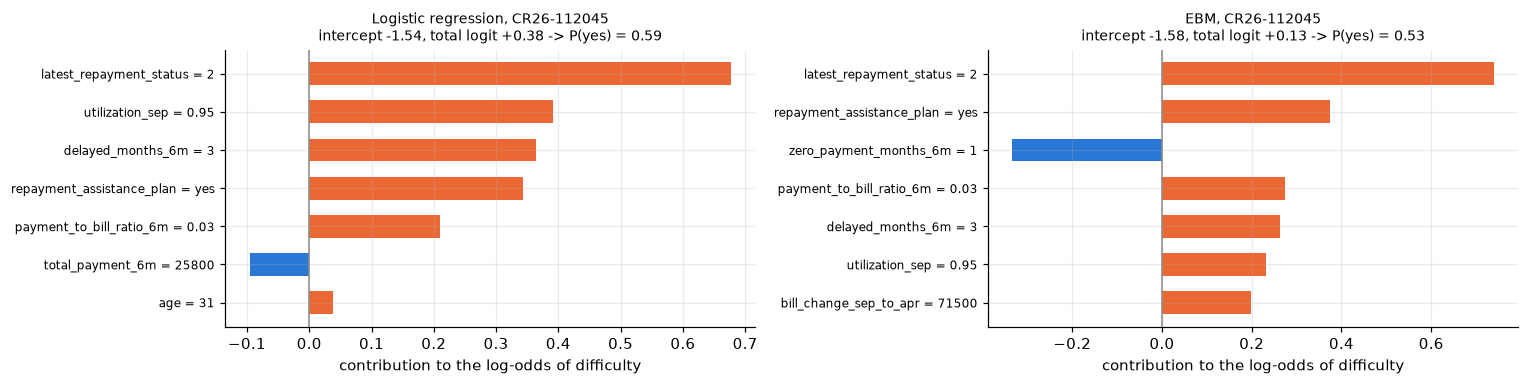

In [25]:
def local_summary(i):
    xi = X.loc[[i]]
    lr_c, _ = lr_contributions(lr, xi)
    ebm_c = pd.Series(ebm.eval_terms(xi)[0], index=ebm.term_names_)
    top = lambda c: ", ".join(f"{f} ({v:+.2f})" for f, v in c.reindex(c.abs().sort_values().index[::-1][:3]).items())
    p = {"GOSDT": gosdt.predict_proba(xi)[0, 1], "Logistic regression": lr.predict_proba(xi)[0, 1], "EBM": ebm.predict_proba(xi)[0, 1]}
    return pd.DataFrame({"P(yes)": p,
                         "prediction": {k: int(classify(k, xi)[0]) for k in MODELS},
                         "main reasons": {"GOSDT": gosdt.leaves(xi).iloc[0], "Logistic regression": top(lr_c.iloc[0]), "EBM": top(ebm_c)}})


with pd.option_context("display.max_colwidth", 200):
    for i in ALL_LOCAL:
        print(f"=== {train.row_id[i]} | true class: {y[i]} ===")
        display(local_summary(i).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
contrib, base = lr_contributions(lr, X.loc[[EXTRA_IDX]])
plot_local(axes[0], contrib.loc[EXTRA_IDX], base, X.loc[EXTRA_IDX], f"Logistic regression, {train.row_id[EXTRA_IDX]}")
plot_local(axes[1], pd.Series(ebm.eval_terms(X.loc[[EXTRA_IDX]])[0], index=ebm.term_names_), ebm.intercept_[0],
           X.loc[EXTRA_IDX], f"EBM, {train.row_id[EXTRA_IDX]}")
plt.tight_layout()
plt.show()

The three final models give the same answer for **94.8%** of the training clients. When all three say "yes", 70% really have difficulty, and when all three say "no", 15.7% do. The disagreements (5% of the clients) have actual rates between 42% and 62%, so the models disagree precisely on the ambiguous clients.

The most common disagreement is **GOSDT says "no" while the logistic regression and the EBM say "yes"** (378 clients, 57% with difficulty). Our extra client **CR26-112045** comes from that group. They are 31, 2 months late right now, late in 3 of the last 6 months, have paid 3% of a large bill (160k on average) that has grown by 71,500 since April, use 95% of the limit and have an assistance plan:

* **Logistic regression (0.59)** and **EBM (0.53)** both say "yes", and their explanations mostly agree: the current status is the main reason (+0.68 and +0.74), followed by the nearly full card, the delays, the plan and the low payment ratio. The EBM also adds +0.20 for the growing bill. The only conflict between the two is the single month without payment: the EBM *subtracts* 0.33 for it (the dip at 1 to 2 months in its curve), while for the logistic regression it is a small push in the other direction.
* **GOSDT** says "no" with only 15.5%, the same leaf as the best clients, because this client passes every check **by the smallest margin**: a payment ratio of exactly 0.03 against the `>= 0.03` threshold, and 3 delayed months, far from the 6 needed. Its explanation ("pays at least 3% and is not late every month") is true, but it ignores that the client is 2 months late right now with the card almost full. This is the typical failure of hard thresholds: they don't see how close a client is to the cut.

The true class is 0, so this time the tree happens to be right, and the additive models are only a little above 0.5. It is still a good example of conflicting explanations: the additive models weigh everything a little, the tree decides on a couple of conditions, and the same client looks like a typical good payer or a borderline risk depending on which model we ask.

For the three fixed clients, the predictions agree in the three models and the direction of the explanations agrees too. What changes is the **reason each model gives**: GOSDT explains CR26-102000 through its age, the logistic regression through its delays and missing payments, and the EBM through both. CR26-129090, the positive with a clean history, is predicted "no" with confidence by the three models, so it is a limit of the data rather than of any model.

### 6.4 Errors by sex (descriptive)

As the data dictionary asks, we only describe these numbers and don't draw fairness conclusions.

In [26]:
# descriptive audit of the out of fold errors by sex (no fairness claim, see the data dictionary)
rows = []
for k in MODELS:
    p = (oof_probs[k] >= THRESHOLD[k]).astype(int)
    for s, g in train.groupby("sex").groups.items():
        yt, yp = y[g], p[train.index.get_indexer(g)]
        rows.append({"model": k, "sex": s, "clients": len(g), "true positive rate": yt.mean(), "predicted positive rate": yp.mean(),
                     "accuracy": accuracy_score(yt, yp), "false positive rate": yp[yt == 0].mean(), "false negative rate": 1 - yp[yt == 1].mean()})
pd.DataFrame(rows).set_index(["model", "sex"]).round(3)

clients  true positive rate  predicted positive rate  accuracy  false positive rate  false negative rate
model               sex                                                                                                             
GOSDT               female    15130               0.208                    0.080     0.817                0.034                0.748
                    male       9870               0.218                    0.090     0.813                0.038                0.723
Logistic regression female    15130               0.208                    0.084     0.816                0.038                0.739
                    male       9870               0.218                    0.099     0.813                0.043                0.702
EBM                 female    15130               0.208                    0.091     0.820                0.040                0.714
                    male       9870               0.218                    0.103     0.818                0.043                0.681

For every model, accuracy differs by less than 0.5 points between women and men. All three predict slightly more positives for men, which is in line with the slightly higher real rate (21.8% vs 20.8%). The false negative rate is somewhat higher for women (0.71 vs 0.68 with the EBM, 0.74 vs 0.70 with the logistic regression) and the false positive rate slightly lower. GOSDT and the logistic regression don't use sex at all and the EBM barely does (±0.015), so these differences come from how the other variables are distributed in each group, not from the models looking at sex.

## 7. Predictions for `test.csv`

We use the model with the best CV accuracy and the threshold chosen in section 6.1. The file keeps all the original columns of `test.csv` and adds `predicted_class` (0/1). It is written to `submission/test.csv` so the original file is not overwritten (otherwise rerunning the notebook would read the predictions back as a feature).

In [27]:
FINAL = max(MODELS, key=lambda k: results[k]["accuracy_mean"])
submission = test.copy()
submission["predicted_class"] = classify(FINAL, X_test)
OUT_DIR = Path("submission")
OUT_DIR.mkdir(exist_ok=True)
submission.to_csv(OUT_DIR / "test.csv", index=False)

print(f"model used: {FINAL} (CV accuracy {results[FINAL]['accuracy_mean']:.4f}), threshold {THRESHOLD[FINAL]}")
print(f"predicted positive rate in test: {submission.predicted_class.mean():.3f} (in train, out of fold: {(oof_probs[FINAL] >= THRESHOLD[FINAL]).mean():.3f})")
print("agreement with the other models on test:",
      {k: round(float((classify(k, X_test) == submission.predicted_class).mean()), 3) for k in MODELS if k != FINAL})
submission[["row_id", "predicted_class"]].head()

model used: EBM (CV accuracy 0.8188), threshold 0.5
predicted positive rate in test: 0.095 (in train, out of fold: 0.096)
agreement with the other models on test: {'GOSDT': 0.967, 'Logistic regression': 0.969}


,row_id,predicted_class
0,CR26-128173,0
1,CR26-102911,0
2,CR26-104960,0
3,CR26-123913,0
4,CR26-111750,0


The EBM predicts 9.5% positives in `test.csv`, almost the same as its out of fold rate on train (9.6%), so the test set looks like the training data. It agrees with the other two models on about 97% of the test clients.

## 8. Conclusions

* **The problem is hard and the signal is narrow.** The best model reaches 0.819 accuracy against 0.788 for the baseline, and almost all of the information is in repayment behaviour: how many months the client was late, whether they are late now, and how much of the bill they pay. The bills, the credit limit and the demographic variables (sex included) contribute little or nothing.
* **The three families tell the same story at different levels of detail.** GOSDT summarises it in three profiles that fit in a sentence each. The lasso logistic regression turns it into 12 coefficients, read as odds ratios or as changes in probability. The EBM draws the full shape of each effect.
* **Each model has its blind spots, and the comparison exposes them.** The tree ignores how close a client is to a threshold (CR26-112045) and can't rank clients (AUC 0.65). The logistic regression can't represent non-monotonic effects: it gets the tail of the payment ratio backwards, misses the U shape of age and changes the sign of a local explanation (months without payment for CR26-126238). The EBM is the most accurate and its shapes agree with the raw data and with the thresholds the tree found independently (age 25, six delayed months, a payment ratio around 1.75 in Phase I CART), but it takes 15 curves to explain, and the weakly supported parts of those curves need care.
* **Predictions for `test.csv`** come from the EBM, the most accurate model in the CV, with the default 0.5 threshold.
* **Possible improvements.** Use the EBM shapes to engineer better features for the other two models: bins or splines for the payment ratio and age in the logistic regression, and a `ratio >= 1.75` indicator among GOSDT's candidate thresholds. Add monotonicity constraints in the EBM where the domain justifies them (delays). We could also choose the threshold for a business goal such as recall instead of accuracy. Some positives, like CR26-129090, are simply not predictable from these variables.